# Phần D — Khi OLS không còn lợi thế

Ở phần A ([variable_type.ipynb](variable_type.ipynb)), OLS luôn ngang hoặc tốt hơn IPTW/AIPW. Đó là do DGP, không phải do phương pháp:

1. **τ đồng nhất.** OLS với một hệ số cho A là trung bình có trọng số của τ(X), trọng số ≈ e(1−e). Khi τ là hằng số thì trung bình nào cũng bằng ATE.
2. **μ0(X) tuyến tính đúng dạng.** Khi đó OLS hiệu quả nhất; IPTW/AIPW chỉ thêm phương sai.
3. **PS logistic với γ = 0.5 gần như tuyến tính** trên miền của X. Vì vậy OLS gần như "double robust": chỉ cần *hoặc* μ0 *hoặc* E[A|X] tuyến tính theo regressor là OLS gần không chệch.
4. Khi mã hóa sai (**T3b**, **T4**, **T6**), PS và outcome dùng chung design sai nên cả ba phương pháp chệch như nhau.

Phần D phá từng lợi thế trên. Phân tích luôn dùng design "tự nhiên" (chặn + X1 + X2 tuyến tính; dummy cho **H2**). Người phân tích không biết dạng của τ(X) hay thành phần phi tuyến.

| Mã | Thay đổi so với **T0** | Phá lợi thế | Kỳ vọng (pilot n = 400.000) |
|---|---|---|---|
| **H0** | τ hằng số, P(A=1) = **0.2** | đối chứng | cả bốn gần không chệch |
| **H1a** | τ(X) = 2 + 0.5·X2, P(A=1) = 0.5 | đối chứng | cả bốn gần không chệch (đối xứng) |
| **H1b** | τ(X) = 2 + 0.5·X2, P(A=1) = **0.2** | 1 | OLS +0.14; IPTW, AIPW, RA ≈ 0 |
| **H2** | X2 danh nghĩa 3 mức, mức hiếm e ≈ 0.9, τ lớn hơn 2 ở mức hiếm | 1 | OLS −0.125; IPTW, AIPW, RA ≈ 0 |
| **H3** | τ(X) = 2 + (X2² − 1)/√2 | 1 + 2 | OLS, RA −0.075; IPTW, AIPW ≈ 0 |
| **M1a/b/c** | μ0 thêm He3(X2) = (X2³ − 3X2)/√6; γ1 = γ2 = 0.5 / 1.0 / 1.5 | 2 + 3 | OLS, RA ≈ 0 / −0.09 / −0.18; IPTW, AIPW ≈ 0 |

**Cách đọc.** Mục 0 gồm những thứ dùng chung, không đổi giữa các kịch bản: estimator, vòng Monte Carlo, hình. Sau đó mỗi kịch bản là một phần tự chứa gồm 6 cell:
(a) công thức DGP; (b) hàm sinh dữ liệu, mỗi dòng khác T0 có chú thích `# KHÁC T0`; (c) bảng so sánh với T0 kèm kiểm tra;
(d) một mẫu rất lớn để thấy giới hạn của từng estimator; (e) Monte Carlo; (f) nhận xét.

Mặc định R = 1000 lần lặp; đặt `RA_VARIABLE_REPS=200` để chạy thử, `RA_VARIABLE_RUN_MC=0` để chỉ đọc lại CSV trong `results/`.

## 0. Phần dùng chung
### 0.1 Thư viện, hằng số, kiểu hình

In [ ]:
import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.special import expit
from scipy.stats import norm
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, LogLocator, NullLocator
from IPython.display import display, Markdown

TAU = 2.0                 # ATE thật ở mọi kịch bản
SIGMA = 1.0
N_REF = 200_000           # mẫu tham chiếu để hiệu chỉnh gamma0 và kiểm tra DGP
N_LARGE = 2_000_000       # một mẫu rất lớn: xấp xỉ giới hạn của từng estimator
N_VALUES = tuple(sorted(int(v) for v in
                        os.environ.get("RA_VARIABLE_N", "250,500,1000,2000,4000,8000").split(",")))
R = int(os.environ.get("RA_VARIABLE_REPS", "1000"))
RUN_MC = os.environ.get("RA_VARIABLE_RUN_MC", "1") != "0"
SEED = 20261021           # trùng phần A, để T0 ở đây tái lập đúng T0 của phần A
METHODS = ("Naive", "OLS", "IPTW", "AIPW", "RA")
ADJUSTED = ("OLS", "IPTW", "AIPW", "RA")
Z95 = norm.ppf(0.975)

RESULT_DIR = next((p for p in (Path.cwd(), Path.cwd() / "scenario/variable_scenario",
                              Path.cwd() / "ra_causal/scenario/variable_scenario")
                   if (p / "ols_unfavorable.ipynb").exists()), None)
if RESULT_DIR is None:
    raise FileNotFoundError("Hãy chạy kernel từ variable_scenario, ra_causal hoặc Seminar.")
RESULT_DIR = RESULT_DIR / "results"
FIG_DIR = RESULT_DIR / "figures_D"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Màu phương pháp giữ như phần A; RA thêm màu tím.
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8a8986"
GRID, SHADE = "#e9e8e4", "#f0efec"
METHOD_STYLE = {
    "Naive": dict(color="#7a7974", marker="x"),
    "OLS":   dict(color="#2a78d6", marker="o"),
    "IPTW":  dict(color="#eb6834", marker="s"),
    "AIPW":  dict(color="#1baf7a", marker="^"),
    "RA":    dict(color="#9b59d0", marker="D"),
}
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlesize": 10, "axes.titleweight": "semibold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "legend.frameon": False, "lines.linewidth": 1.8, "lines.markersize": 5.5,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
print(f"R={R}; n={N_VALUES}; chạy MC={RUN_MC}; results={RESULT_DIR}")

R=1000; n=(250, 500, 1000, 2000, 4000, 8000); chạy MC=True; results=/home/doan/Seminar/ra_causal/scenario/variable_scenario/results


### 0.2 Mốc T0 và bước sinh A, Y dùng chung

**T0** (giống phần A):

$$
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + 0.5X_2,\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2,\qquad
\tau(X) = 2,\qquad X_1, X_2 \sim N(0,1)
$$

Mọi kịch bản dùng chung bước cuối:

$$
A \sim \text{Bernoulli}\big(e(X)\big),\qquad Y = \mu_0(X) + \tau(X)\,A + \varepsilon,\quad \varepsilon \sim N(0, 1)
$$

Mỗi kịch bản chỉ viết lại hàm `dgp_<mã>(n, rng)`. Hàm này trả về X, phần tuyến tính của logit PS (chưa có γ0), μ0(X) và τ(X).
γ0 được hiệu chỉnh trên mẫu tham chiếu N_REF để P(A=1) đạt mục tiêu. `simulate` không đổi giữa các kịch bản.

In [2]:
def calibrate_gamma0(lin, target=0.5):
    # Chia đôi: chọn gamma0 sao cho mean(expit(gamma0 + lin)) = target.
    lo, hi = -50., 50.
    for _ in range(60):
        mid = (lo + hi) / 2
        if expit(mid + lin).mean() < target:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


def reference_sample(dgp):
    # Mẫu tham chiếu cố định (seed 12345), độc lập với Monte Carlo.
    return dgp(N_REF, np.random.default_rng(12345))


def gamma0_for(dgp, target=0.5):
    _, lin, _, _ = reference_sample(dgp)
    return calibrate_gamma0(lin, target)


def simulate(dgp, gamma0, n, seed):
    # Bước chung: A ~ Bernoulli(e(X)), Y = mu0 + tau*A + eps. Truth giữ riêng.
    rng = np.random.default_rng(seed)
    X, lin, mu0, tau = dgp(n, rng)
    e = expit(gamma0 + lin)
    a = rng.binomial(1, e)
    eps = rng.normal(0, SIGMA, n)
    df = pd.DataFrame({**X, "A": a, "Y": mu0 + tau * a + eps})
    truth = pd.DataFrame({"e": e, "tau": tau, "Y0": mu0 + eps, "Y1": mu0 + tau + eps})
    return df, truth


def dgp_T0(n, rng):
    x1 = rng.normal(size=n)
    x2 = rng.normal(size=n)
    lin = 0.5*x1 + 0.5*x2             # logit e(X) - gamma0
    mu0 = 0.5*x1 + 0.5*x2             # mu0(X)
    tau = np.full(n, TAU)             # tau(X) = 2
    return {"X1": x1, "X2": x2}, lin, mu0, tau


GAMMA0_T0 = gamma0_for(dgp_T0, target=0.5)


def simulate_T0(n, seed):
    return simulate(dgp_T0, GAMMA0_T0, n, seed)


def design_linear(df):
    # Design người phân tích dùng: chặn + X1 + X2 tuyến tính.
    return np.column_stack([np.ones(len(df)), df.X1, df.X2])


FORMULA_T0 = {"X2": "N(0,1)", "logit e(X)": "γ0 + 0.5·X1 + 0.5·X2",
              "μ0(X)": "0.5·X1 + 0.5·X2", "τ(X)": "2", "P(A=1) mục tiêu": "0.5"}
print(f"T0: gamma0 = {GAMMA0_T0:.4f}")

T0: gamma0 = -0.0012


### 0.3 Năm estimator

| Phương pháp | Ước lượng | SE |
|---|---|---|
| Naive | $\bar Y_1 - \bar Y_0$ | Welch |
| OLS | hệ số của A trong $Y \sim 1 + X + A$ | HC1 |
| IPTW (Hájek) | $\dfrac{\sum A_iY_i/\hat e_i}{\sum A_i/\hat e_i} - \dfrac{\sum (1-A_i)Y_i/(1-\hat e_i)}{\sum (1-A_i)/(1-\hat e_i)}$ | IF có hiệu chỉnh việc ước lượng $\hat e$ |
| AIPW | $\frac1n\sum_i \Big[\hat m_1 - \hat m_0 + \frac{A_i(Y_i-\hat m_1)}{\hat e_i} - \frac{(1-A_i)(Y_i-\hat m_0)}{1-\hat e_i}\Big]$ | $\mathrm{SD}(\psi_i)/\sqrt n$ |
| **RA** (mới) | $\frac1n\sum_i \big[\hat m_1(X_i) - \hat m_0(X_i)\big]$ | IF của hệ estimating equations (bên dưới) |

$\hat m_t$ là OLS fit riêng trên nhóm $A = t$ với cùng design, dùng chung cho AIPW và RA. RA tương đương hồi quy có tương tác A×X với X đã tâm hóa (Lin 2013).

**Estimand mà OLS nhắm tới** khi τ(X) thay đổi: xấp xỉ $E[w(X)\,\tau(X)]/E[w(X)]$ với $w(X) = e(X)(1-e(X))$ (Angrist 1998; đúng chính xác khi design bão hòa).
Trọng số này dồn vào vùng e ≈ 0.5. Vì vậy OLS chỉ chệch khi τ(X) khác nhau giữa vùng e ≈ 0.5 và vùng e gần 0 hoặc 1.

**SE của RA.** $\hat\theta = \frac1n\sum X_i^\top(\hat b_1 - \hat b_0)$, $M_t = \frac1n\sum_i 1(A_i=t)X_iX_i^\top$, $\bar X = \frac1n\sum X_i$:

$$
\psi_i = X_i^\top(\hat b_1-\hat b_0) - \hat\theta
+ \bar X^\top M_1^{-1} X_i\, A_i\,(Y_i - \hat m_1(X_i))
- \bar X^\top M_0^{-1} X_i\, (1-A_i)\,(Y_i - \hat m_0(X_i))
$$

Công thức đúng cả khi mô hình outcome sai dạng (sandwich), nên coverage của RA phản ánh bias, không phải SE sai.

Naive, OLS, IPTW, `fit_propensity` copy nguyên từ phần A. Ở AIPW, phần fit outcome được tách thành `_arm_predictions` để RA dùng chung.

In [3]:
class FitFailure(ValueError):
    pass


def _check_rank(design):
    if np.linalg.matrix_rank(design) < design.shape[1]:
        raise FitFailure("rank_deficient")


def fit_propensity(A, design):
    x = np.asarray(design, float)
    _check_rank(x)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        fit = sm.Logit(A, x).fit(disp=False, maxiter=100)
    if any(issubclass(w.category, PerfectSeparationWarning) for w in caught):
        raise FitFailure("perfect_separation")
    if not fit.mle_retvals.get("converged", False):
        raise FitFailure("ps_not_converged")
    e = np.asarray(fit.predict(x))
    if not np.isfinite(e).all() or np.any((e <= 0) | (e >= 1)):
        raise FitFailure("ps_at_boundary")
    return e  # không clip, không regularize


def est_naive(Y, A, design):
    y1, y0 = Y[A == 1], Y[A == 0]
    if min(len(y1), len(y0)) < 2:
        raise FitFailure("treatment_group_too_small")
    return y1.mean() - y0.mean(), np.sqrt(y1.var(ddof=1)/len(y1) + y0.var(ddof=1)/len(y0))


def est_ols(Y, A, design):
    x = np.column_stack([np.asarray(design), A])
    _check_rank(x)
    fit = sm.OLS(Y, x).fit(cov_type="HC1")
    return fit.params[-1], fit.bse[-1]


def est_iptw(Y, A, design, e_hat=None):
    x = np.asarray(design, float)
    e = fit_propensity(A, x) if e_hat is None else e_hat
    w1, w0 = A/e, (1-A)/(1-e)
    mu1, mu0 = (w1 @ Y)/w1.sum(), (w0 @ Y)/w0.sum()
    psi = w1*(Y-mu1)/w1.mean() - w0*(Y-mu0)/w0.mean()
    a1 = x.T @ (-w1*(Y-mu1)*(1-e)) / len(Y) / w1.mean()
    a0 = x.T @ (w0*(Y-mu0)*e) / len(Y) / w0.mean()
    information = (x * (e*(1-e))[:, None]).T @ x / len(Y)
    score = x * (A-e)[:, None]
    influence = psi + score @ np.linalg.solve(information, a1-a0)
    return mu1-mu0, influence.std(ddof=1)/np.sqrt(len(Y))


def _arm_predictions(Y, A, x):
    # OLS riêng từng nhóm điều trị; trả về m0_hat(X), m1_hat(X) cho mọi quan sát.
    predictions = {}
    for t in (0, 1):
        xt = x[A == t]
        _check_rank(xt)
        if len(xt) <= x.shape[1]:
            raise FitFailure("outcome_group_too_small")
        b = np.linalg.lstsq(xt, Y[A == t], rcond=None)[0]
        predictions[t] = x @ b
    return predictions[0], predictions[1]


def est_aipw(Y, A, design, e_hat=None):
    x = np.asarray(design, float)
    e = fit_propensity(A, x) if e_hat is None else e_hat
    m0, m1 = _arm_predictions(Y, A, x)
    psi = m1-m0 + A*(Y-m1)/e - (1-A)*(Y-m0)/(1-e)
    return psi.mean(), psi.std(ddof=1)/np.sqrt(len(Y))


def est_ra(Y, A, design):
    x = np.asarray(design, float)
    n = len(Y)
    m0, m1 = _arm_predictions(Y, A, x)
    theta = np.mean(m1 - m0)
    xbar = x.mean(0)
    psi = m1 - m0 - theta
    for t, sign, m in ((1, 1., m1), (0, -1., m0)):
        at = (A == t).astype(float)
        M = (x * at[:, None]).T @ x / n
        psi = psi + sign * (x @ np.linalg.solve(M, xbar)) * at * (Y - m)
    return theta, psi.std(ddof=1)/np.sqrt(n)


def estimate_all(df, design):
    Y, A = df.Y.to_numpy(), df.A.to_numpy()
    x = np.asarray(design, float)
    estimates, status = {}, {}
    failure_types = (FitFailure, np.linalg.LinAlgError, ValueError,
                     sm.tools.sm_exceptions.PerfectSeparationError)

    def record(method, call):
        try:
            value = tuple(float(v) for v in call())
            if not np.isfinite(value).all() or value[1] < 0:
                raise FitFailure("nonfinite_estimate_or_se")
            estimates[method], status[method] = value, "ok"
        except failure_types as exc:
            estimates[method], status[method] = (np.nan, np.nan), str(exc)

    record("Naive", lambda: est_naive(Y, A, x))
    record("OLS", lambda: est_ols(Y, A, x))
    try:
        e, ps_status = fit_propensity(A, x), "ok"
    except failure_types as exc:
        e, ps_status = None, str(exc)
    for method, fn in (("IPTW", est_iptw), ("AIPW", est_aipw)):
        if e is None:
            estimates[method], status[method] = (np.nan, np.nan), ps_status
        else:
            record(method, lambda fn=fn: fn(Y, A, x, e))
    record("RA", lambda: est_ra(Y, A, x))   # RA không cần PS
    return estimates, e, status, ps_status

### 0.4 Công cụ: so sánh DGP, mẫu lớn, Monte Carlo, tóm tắt

- `show_vs_base`: in bảng công thức kịch bản cạnh mốc, kèm số trên mẫu tham chiếu (γ0, P(A=1), E[τ], SD[τ], ESS/n với e thật). Kiểm tra E[τ] = 2 và P(A=1) đúng mục tiêu bằng `assert`.
- `large_sample_check`: một mẫu n = 2.000.000. Bias ở đây xấp xỉ **giới hạn** của từng estimator khi n → ∞. Bias OLS ở đây (`ols_bias`) là mốc để đối chiếu với Monte Carlo.
- `run_mc`: `SeedSequence([SEED, mã, n]).spawn(R)` như phần A; lưu `results/D_<mã>.csv` và `results/D_<mã>_diagnostics.csv`.
- `report`: bảng tóm tắt theo n, kiểm tra bias OLS so với `ols_bias`, hai hình.

In [4]:
def ess_ratio(w):
    return w.sum()**2/(w @ w)/len(w)


def show_vs_base(name, formulas, dgp, gamma0, target, base="T0", base_formulas=FORMULA_T0,
                 base_dgp=dgp_T0, base_gamma0=None):
    # Bảng công thức + số trên mẫu tham chiếu; assert E[tau] = 2 và P(A=1) = mục tiêu.
    base_gamma0 = GAMMA0_T0 if base_gamma0 is None else base_gamma0
    rows = {}
    for label, (f, d, g0) in {base: (base_formulas, base_dgp, base_gamma0),
                              name: (formulas, dgp, gamma0)}.items():
        _, lin, _, tau = reference_sample(d)
        e = expit(g0 + lin)
        # ESS/n Kish với e thật: E[w] = 2, E[w²] = E[1/e + 1/(1-e)].
        ess = 4 / np.mean(1/e + 1/(1-e))
        rows[label] = {**f, "γ0": f"{g0:+.4f}", "P(A=1) trên mẫu tham chiếu": f"{e.mean():.4f}",
                       "E[τ]": f"{tau.mean():.4f}", "SD[τ]": f"{tau.std():.3f}",
                       "ESS/n kỳ vọng (e thật)": f"{ess:.2f}"}
    table = pd.DataFrame(rows)
    table["khác"] = np.where(table[base] != table[name], "◆", "")
    display(Markdown(f"**{name} so với {base}** (◆ = khác)"))
    display(table)
    _, lin, _, tau = reference_sample(dgp)
    e = expit(gamma0 + lin)
    assert abs(tau.mean() - TAU) < 1e-2, f"E[tau] = {tau.mean():.4f} khác 2"
    assert abs(e.mean() - target) < 5e-3, f"P(A=1) = {e.mean():.4f} khác {target}"
    print(f"Kiểm tra {name}: E[τ] ≈ 2, P(A=1) ≈ {target}: PASS")
    return reference_sample(dgp)


def large_sample_check(simulate_fn, design_fn, expected=None, seed=7):
    # Một mẫu N_LARGE: bias ≈ giới hạn của từng estimator khi n → ∞.
    df, truth = simulate_fn(N_LARGE, seed)
    estimates, e, status, _ = estimate_all(df, design_fn(df))
    rows = []
    for m in METHODS:
        est, se = estimates[m]
        row = {"method": m, "ước lượng": est, "bias": est - TAU, "SE": se}
        if expected is not None and m in expected:
            row["kỳ vọng (pilot)"] = expected[m]
            row["lệch"] = est - TAU - expected[m]
        rows.append(row)
    table = pd.DataFrame(rows).set_index("method")
    display(Markdown(f"**Một mẫu n = {N_LARGE:,}** — SATE = {truth.tau.mean():.4f}, "
                     f"P(A=1) = {df.A.mean():.3f}, ESS/n = "
                     f"{ess_ratio(np.where(df.A == 1, 1/e, 1/(1-e))):.2f}"))
    display(table.round(4))
    if "lệch" in table and (table["lệch"].abs() > .02).any():
        print("Cảnh báo: có estimator lệch pilot quá 0.02 — xem lại tham số.")
    return {"ols_bias": float(table.loc["OLS", "bias"]), "ols_se": float(table.loc["OLS", "SE"]),
            "table": table}


def scenario_code(name):
    return sum((i+1)*ord(c) for i, c in enumerate(name))


def run_mc(simulate_fn, design_fn, name, n_values=N_VALUES, R=R, run=RUN_MC):
    path, dpath = RESULT_DIR / f"D_{name}.csv", RESULT_DIR / f"D_{name}_diagnostics.csv"
    if not run:
        return pd.read_csv(path), pd.read_csv(dpath)
    rows, diags = [], []
    start = time.perf_counter()
    for n in n_values:
        for rep, child in enumerate(np.random.SeedSequence([SEED, scenario_code(name), n]).spawn(R)):
            df, truth = simulate_fn(n, child)
            estimates, e, status, ps_status = estimate_all(df, design_fn(df))
            key = dict(scenario=name, n=n, rep=rep)
            for m, (est, se) in estimates.items():
                rows.append({**key, "method": m, "est": est, "se": se, "truth": TAU, "status": status[m]})
            d = {**key, "ps_status": ps_status, "treated_rate": df.A.mean(), "sate": truth.tau.mean(),
                 "e_min": np.nan, "e_max": np.nan, "max_weight": np.nan, "ess_ratio": np.nan}
            if e is not None:
                w = np.where(df.A == 1, 1/e, 1/(1-e))
                d.update(e_min=e.min(), e_max=e.max(), max_weight=w.max(), ess_ratio=ess_ratio(w))
            diags.append(d)
    rows, diags = pd.DataFrame(rows), pd.DataFrame(diags)
    rows.to_csv(path, index=False)
    diags.to_csv(dpath, index=False)
    print(f"{name}: n={list(n_values)}, R={R} — {time.perf_counter()-start:.0f}s")
    return rows, diags


def summarize(raw):
    out = []
    for (n, m), g in raw.groupby(["n", "method"], sort=False):
        ok = g.status.eq("ok") & np.isfinite(g.est) & np.isfinite(g.se)
        est, se = g.est[ok].to_numpy(), g.se[ok].to_numpy()
        sd = est.std(ddof=1) if len(est) > 1 else np.nan
        out.append({"n": n, "method": m, "R": len(g), "valid_reps": int(ok.sum()),
                    "failure_rate": (~ok).mean(),
                    "bias": np.mean(est - TAU) if len(est) else np.nan,
                    "mc_se_bias": sd/np.sqrt(len(est)) if len(est) else np.nan,
                    "emp_sd": sd, "mean_se": se.mean() if len(est) else np.nan,
                    "se_sd_ratio": se.mean()/sd if sd > 0 else np.nan,
                    "rmse": np.sqrt(np.mean((est - TAU)**2)) if len(est) else np.nan,
                    "coverage": np.mean(np.abs(est - TAU) <= Z95*se) if len(est) else np.nan})
    return pd.DataFrame(out)


def summarize_diag(diag):
    g = diag.groupby("n")
    out = g[["treated_rate", "sate", "e_min", "e_max", "max_weight", "ess_ratio"]].mean()
    out["ps_failure_rate"] = g.ps_status.apply(lambda s: s.ne("ok").mean())
    return out


def n_star(summary, method):
    # n nhỏ nhất mà từ đó trở đi RMSE(method) < RMSE(OLS); None nếu không có.
    r = summary.pivot(index="n", columns="method", values="rmse").sort_index()
    below = (r[method] < r["OLS"]).to_numpy()
    for i in range(len(below)):
        if below[i:].all():
            return int(r.index[i])
    return None

### 0.5 Hình
- `plot_metrics_vs_n`: bias ± 1.96·MC SE (đường gạch xanh = giới hạn OLS từ mẫu lớn), RMSE (log, đường chấm ∝ 1/√n), coverage, SE/SD.
- `plot_rmse_ratio`: RMSE của IPTW, AIPW, RA chia cho RMSE của OLS. Dưới 1 nghĩa là thắng OLS.

In [5]:
def style_n_axis(ax, ns):
    ax.set_xscale("log")
    ax.set_xticks(list(ns))
    ax.set_xticklabels([f"{n:,}" for n in ns], rotation=30)
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(min(ns)/1.25, max(ns)*1.25)


def log_y(ax):
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(subs=(1, 2, 5), numticks=12))
    ax.yaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))


def plot_metrics_vs_n(summary, name, ols_bias, methods=ADJUSTED):
    ns = sorted(summary.n.unique())
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), layout="constrained")
    ax_b, ax_r, ax_c, ax_s = axes
    band = Z95*np.sqrt(.95*.05/summary.R.max())
    ax_b.axhline(0, color=INK_2, lw=.8)
    ax_b.axhline(ols_bias, color=METHOD_STYLE["OLS"]["color"], lw=1, ls="--")
    ax_c.axhspan(.95 - band, .95 + band, color=SHADE, lw=0)
    ax_c.axhline(.95, color=INK_2, lw=.8, ls="--")
    ax_s.axhline(1, color=INK_2, lw=.8, ls="--")
    for m in methods:
        g = summary[summary.method.eq(m)].sort_values("n")
        st = METHOD_STYLE[m]
        ax_b.errorbar(g.n, g.bias, yerr=Z95*g.mc_se_bias, capsize=2, **st)
        ax_r.plot(g.n, g.rmse, **st)
        ax_c.plot(g.n, g.coverage, **st)
        ax_s.plot(g.n, g.se_sd_ratio, **st)
    first = summary[summary.method.isin(methods) & summary.n.eq(ns[0])].rmse.min()
    grid = np.array(ns, float)
    ax_r.plot(grid, first*np.sqrt(grid[0]/grid), color=INK_3, ls=":", lw=1.2)
    log_y(ax_r)
    ax_c.set_ylim(max(-.02, min(.8, summary[summary.method.isin(methods)].coverage.min() - .05)), 1.005)
    for ax, t in zip(axes, ("Bias ± 1.96·MC SE", "RMSE (log)", "Coverage CI 95%", "SE / SD thực nghiệm")):
        style_n_axis(ax, ns)
        ax.set_title(t)
        ax.set_xlabel("n")
    handles = [Line2D([], [], label=m, **METHOD_STYLE[m]) for m in methods]
    handles += [Line2D([], [], color=METHOD_STYLE["OLS"]["color"], ls="--", lw=1,
                       label=f"giới hạn OLS ({ols_bias:+.3f})"),
                Line2D([], [], color=INK_3, ls=":", label="∝ 1/√n"),
                Patch(color=SHADE, label="0.95 ± 1.96 MC SE")]
    fig.legend(handles=handles, loc="outside lower center", ncol=len(handles))
    fig.suptitle(f"{name} — chất lượng ước lượng theo n", x=0.01, ha="left")
    fig.savefig(FIG_DIR / f"{name}_metrics.png", bbox_inches="tight")
    plt.show()


def plot_rmse_ratio(summary, name, methods=("IPTW", "AIPW", "RA")):
    ns = sorted(summary.n.unique())
    r = summary.pivot(index="n", columns="method", values="rmse").sort_index()
    fig, ax = plt.subplots(figsize=(6.2, 3.4), layout="constrained")
    ax.axhline(1, color=INK_2, lw=.8, ls="--")
    for m in methods:
        ax.plot(r.index, r[m]/r["OLS"], label=m, **METHOD_STYLE[m])
    style_n_axis(ax, ns)
    log_y(ax)
    stars = ", ".join(f"{m}: {n_star(summary, m) or '—'}" for m in methods)
    ax.set_title(f"RMSE / RMSE(OLS)  ·  n* {stars}")
    ax.set_xlabel("n")
    ax.legend(loc="best")
    fig.suptitle(f"{name} — dưới 1 là thắng OLS", x=0.01, ha="left")
    fig.savefig(FIG_DIR / f"{name}_rmse_ratio.png", bbox_inches="tight")
    plt.show()


RESULTS = {}   # name -> (summary, diag_summary, large-sample limit)


def report(name, raw, diag, limit):
    summary, dsum = summarize(raw), summarize_diag(diag)
    wide = (summary[summary.method.isin(ADJUSTED)]
            .pivot(index="n", columns="method", values=["bias", "rmse", "coverage", "se_sd_ratio"])
            .reindex(columns=list(ADJUSTED), level=1))
    display(Markdown(f"**{name}: bias, RMSE, coverage, SE/SD theo n** (R = {summary.R.max()})"))
    display(wide.round(3))
    fails = summary.pivot(index="n", columns="method", values="failure_rate")
    display(Markdown("**Chẩn đoán trung bình qua rep** (ESS/n, trọng số lớn nhất, tỉ lệ lỗi fit PS)"))
    display(dsum.join(fails.add_prefix("fail_")).round(3))
    ols = summary[summary.method.eq("OLS")].set_index("n")
    tol = 3*np.sqrt(ols.mc_se_bias**2 + limit["ols_se"]**2)
    within = (ols.bias - limit["ols_bias"]).abs() <= tol
    print(f"Bias OLS (MC) nằm trong 3 SE quanh giới hạn {limit['ols_bias']:+.4f} ở "
          f"{int(within.sum())}/{len(within)} giá trị n" + ("" if within.all()
          else f"; lệch ở n = {list(ols.index[~within])}"))
    plot_metrics_vs_n(summary, name, limit["ols_bias"])
    plot_rmse_ratio(summary, name)
    RESULTS[name] = (summary.assign(scenario=name), dsum.assign(scenario=name), limit)
    return summary

### 0.6 Kiểm tra: T0 ở đây tái lập đúng T0 của phần A

`simulate_T0` rút số ngẫu nhiên theo đúng thứ tự của phần A, γ0 hiệu chỉnh trên cùng mẫu tham chiếu, và SEED trùng.
Vì vậy 200 rep đầu ở n = 500 và 2000 phải cho **đúng** cùng ước lượng OLS/IPTW/AIPW như `results/T0.csv`.
Cùng lúc kiểm tra SE của RA: SE/SD gần 1.

In [6]:
part_a = pd.read_csv(RESULT_DIR / "T0.csv")
check_rows = []
for n in (500, 2000):
    for rep, child in enumerate(np.random.SeedSequence([SEED, scenario_code("T0"), n]).spawn(1000)[:200]):
        df, _ = simulate_T0(n, child)
        estimates, *_ = estimate_all(df, design_linear(df))
        for m, (est, se) in estimates.items():
            check_rows.append({"n": n, "rep": rep, "method": m, "est": est, "se": se})
check = pd.DataFrame(check_rows)
merged = check.merge(part_a[["n", "rep", "method", "est", "se"]], on=["n", "rep", "method"],
                     suffixes=("", "_A"))
assert len(merged) == 2*200*4, "thiếu dòng khi ghép với phần A"
np.testing.assert_allclose(merged.est, merged.est_A, rtol=1e-10)
np.testing.assert_allclose(merged.se, merged.se_A, rtol=1e-10)
print("T0 tái lập đúng phần A (OLS/IPTW/AIPW/Naive, 400 rep): PASS")
ra = check[check.method.eq("RA")].groupby("n").agg(bias=("est", lambda s: s.mean() - TAU),
                                                    sd=("est", "std"), mean_se=("se", "mean"))
ra["se_sd_ratio"] = ra.mean_se / ra.sd
display(Markdown("**RA trên T0, 200 rep** (SE/SD nên trong khoảng 0.9–1.1)"))
display(ra.round(4))

T0 tái lập đúng phần A (OLS/IPTW/AIPW/Naive, 400 rep): PASS


**RA trên T0, 200 rep** (SE/SD nên trong khoảng 0.9–1.1)

,bias,sd,mean_se,se_sd_ratio
n,,,,
500,0.0058,0.0966,0.0946,0.9791
2000,0.0001,0.0464,0.0471,1.0151


## H0 — τ hằng số, tỉ lệ điều trị 20% (đối chứng)

$$
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + 0.5X_2,\quad \mathbf{P(A=1) = 0.2},\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2,\qquad \tau(X) = 2
$$

**Câu hỏi:** chỉ lệch tỉ lệ điều trị (không có heterogeneity) có làm OLS chệch không?
**Kỳ vọng:** không. Cả bốn phương pháp gần không chệch; IPTW/AIPW có SD lớn hơn vì ESS/n giảm còn khoảng 0.5.

In [7]:
def dgp_H0(n, rng):
    x1 = rng.normal(size=n)
    x2 = rng.normal(size=n)
    lin = 0.5*x1 + 0.5*x2
    mu0 = 0.5*x1 + 0.5*x2
    tau = np.full(n, TAU)
    return {"X1": x1, "X2": x2}, lin, mu0, tau


GAMMA0_H0 = gamma0_for(dgp_H0, target=0.2)      # KHÁC T0: P(A=1) = 0.2 thay vì 0.5


def simulate_H0(n, seed):
    return simulate(dgp_H0, GAMMA0_H0, n, seed)

In [8]:
_ = show_vs_base("H0", {**FORMULA_T0, "P(A=1) mục tiêu": "0.2"}, dgp_H0, GAMMA0_H0, target=0.2)

**H0 so với T0** (◆ = khác)

,T0,H0,khác
X2,"N(0,1)","N(0,1)",
logit e(X),γ0 + 0.5·X1 + 0.5·X2,γ0 + 0.5·X1 + 0.5·X2,
μ0(X),0.5·X1 + 0.5·X2,0.5·X1 + 0.5·X2,
τ(X),2,2,
P(A=1) mục tiêu,0.5,0.2,◆
γ0,-0.0012,-1.5270,◆
P(A=1) trên mẫu tham chiếu,0.5000,0.2000,◆
E[τ],2.0000,2.0000,
SD[τ],0.000,0.000,
ESS/n kỳ vọng (e thật),0.88,0.49,◆


Kiểm tra H0: E[τ] ≈ 2, P(A=1) ≈ 0.2: PASS


In [9]:
LIMIT_H0 = large_sample_check(simulate_H0, design_linear,
                              expected={"OLS": 0., "IPTW": 0., "AIPW": 0., "RA": 0.})

**Một mẫu n = 2,000,000** — SATE = 2.0000, P(A=1) = 0.199, ESS/n = 0.49

,ước lượng,bias,SE,kỳ vọng (pilot),lệch
method,,,,,
Naive,2.4637,0.4637,0.0021,NaN,NaN
OLS,2.0018,0.0018,0.0018,0.0,0.0018
IPTW,2.0009,0.0009,0.0022,0.0,0.0009
AIPW,2.0012,0.0012,0.0020,0.0,0.0012
RA,2.0014,0.0014,0.0020,0.0,0.0014


H0: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 37s


**H0: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                        rmse                      coverage                      se_sd_ratio                     
method    OLS   IPTW   AIPW     RA    OLS   IPTW   AIPW     RA      OLS   IPTW   AIPW     RA         OLS   IPTW   AIPW     RA
n                                                                                                                            
250     0.001  0.009  0.002  0.005  0.161  0.206  0.183  0.174    0.950  0.936  0.945  0.942       1.020  0.921  0.962  1.005
500     0.003  0.008  0.003  0.003  0.118  0.144  0.133  0.130    0.942  0.933  0.936  0.936       0.981  0.950  0.949  0.959
1000    0.005  0.005  0.005  0.006  0.081  0.103  0.090  0.087    0.949  0.947  0.955  0.958       1.012  0.944  0.995  1.007
2000    0.001  0.002  0.002  0.002  0.059  0.072  0.065  0.064    0.952  0.948  0.951  0.945       0.988  0.973  0.990  0.981
4000    0.001  0.001  0.001 -0.000  0.041  0.049  0.044  0.043    0.953  0.956  0.956  0.955       0.992  1.013  1.022  1.018
8000    0.001  0.002  0.001  0.001  0.029  0.034  0.031  0.031    0.948  0.945  0.954  0.951       1.011  1.025  1.026  1.011

**Chẩn đoán trung bình qua rep** (ESS/n, trọng số lớn nhất, tỉ lệ lỗi fit PS)

,treated_rate,sate,e_min,e_max,max_weight,ess_ratio,ps_failure_rate,fail_AIPW,fail_IPTW,fail_Naive,fail_OLS,fail_RA
n,,,,,,,,,,,,
250,0.201,2.0,0.031,0.628,18.328,0.486,0.0,0.0,0.0,0.0,0.0,0.0
500,0.200,2.0,0.026,0.652,20.474,0.487,0.0,0.0,0.0,0.0,0.0,0.0
1000,0.199,2.0,0.023,0.680,23.502,0.486,0.0,0.0,0.0,0.0,0.0,0.0
2000,0.200,2.0,0.019,0.712,26.703,0.488,0.0,0.0,0.0,0.0,0.0,0.0
4000,0.200,2.0,0.017,0.735,30.726,0.488,0.0,0.0,0.0,0.0,0.0,0.0
8000,0.200,2.0,0.015,0.758,34.476,0.487,0.0,0.0,0.0,0.0,0.0,0.0


Bias OLS (MC) nằm trong 3 SE quanh giới hạn +0.0018 ở 6/6 giá trị n


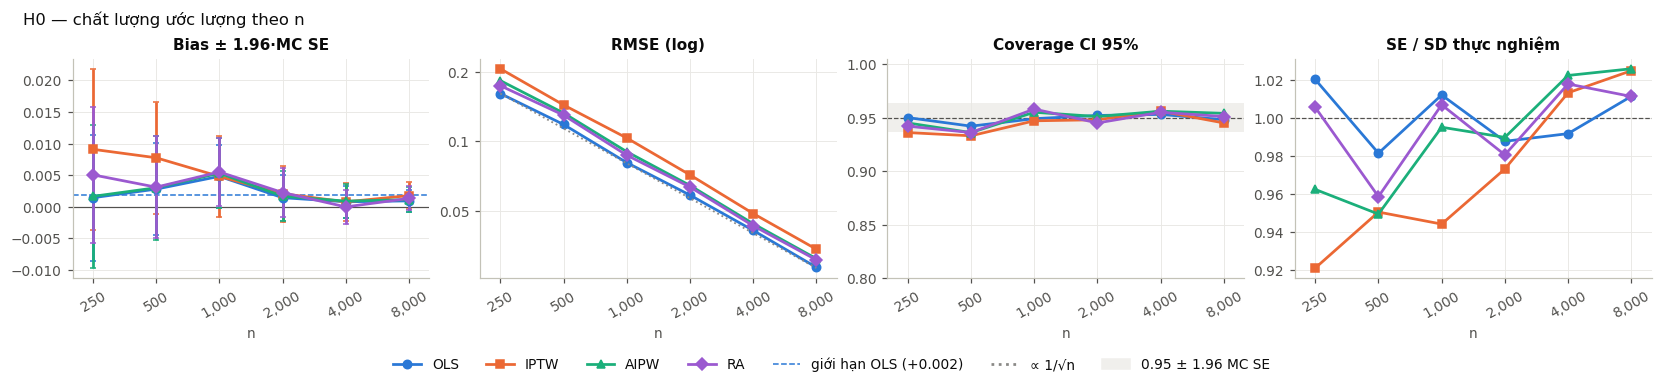

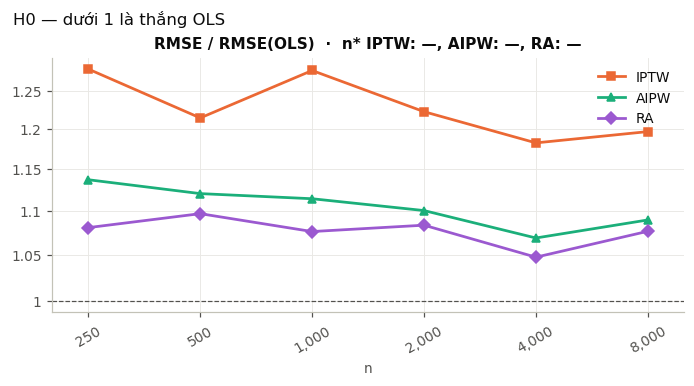

In [10]:
raw_H0, diag_H0 = run_mc(simulate_H0, design_linear, "H0")
summary_H0 = report("H0", raw_H0, diag_H0, LIMIT_H0)

**Nhận xét H0.**
- **Kỳ vọng:** cả bốn gần không chệch, IPTW/AIPW có SD lớn hơn.
- **Kết quả:** bias của OLS, IPTW, AIPW, RA đều trong khoảng ±0.01 ở mọi n; coverage 0.93–0.96. ESS/n = 0.49 nên RMSE của IPTW cao hơn OLS khoảng 15–30% (n = 250: 0.206 so với 0.161), AIPW và RA nằm giữa. Không estimator nào thắng OLS ở bất kỳ n nào.
- **Giải thích:** τ hằng số nên trọng số e(1−e) của OLS không ảnh hưởng tới bias. Lệch tỉ lệ điều trị chỉ làm overlap kém đi, và phần thiệt đó rơi vào các phương pháp dùng trọng số.

## H1a — τ thay đổi tuyến tính theo X2, tỉ lệ điều trị 50% (đối chứng)

$$
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + 0.5X_2,\quad P(A=1) = 0.5,\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2,\qquad \boldsymbol{\tau(X) = 2 + 0.5X_2}
$$

**Câu hỏi:** chỉ có heterogeneity (P(A=1) vẫn 0.5) có làm OLS chệch không?
**Kỳ vọng:** không. Với P(A=1) = 0.5 và X đối xứng, trọng số e(1−e) đối xứng quanh X2 = 0, còn 0.5·X2 là hàm lẻ, nên trung bình có trọng số vẫn bằng 2.

In [11]:
def dgp_H1a(n, rng):
    x1 = rng.normal(size=n)
    x2 = rng.normal(size=n)
    lin = 0.5*x1 + 0.5*x2
    mu0 = 0.5*x1 + 0.5*x2
    tau = TAU + 0.5*x2                          # KHÁC T0: tau(X) = 2 + 0.5 X2
    return {"X1": x1, "X2": x2}, lin, mu0, tau


GAMMA0_H1a = gamma0_for(dgp_H1a, target=0.5)


def simulate_H1a(n, seed):
    return simulate(dgp_H1a, GAMMA0_H1a, n, seed)

In [12]:
_ = show_vs_base("H1a", {**FORMULA_T0, "τ(X)": "2 + 0.5·X2"}, dgp_H1a, GAMMA0_H1a, target=0.5)

**H1a so với T0** (◆ = khác)

,T0,H1a,khác
X2,"N(0,1)","N(0,1)",
logit e(X),γ0 + 0.5·X1 + 0.5·X2,γ0 + 0.5·X1 + 0.5·X2,
μ0(X),0.5·X1 + 0.5·X2,0.5·X1 + 0.5·X2,
τ(X),2,2 + 0.5·X2,◆
P(A=1) mục tiêu,0.5,0.5,
γ0,-0.0012,-0.0012,
P(A=1) trên mẫu tham chiếu,0.5000,0.5000,
E[τ],2.0000,2.0004,◆
SD[τ],0.000,0.500,◆
ESS/n kỳ vọng (e thật),0.88,0.88,


Kiểm tra H1a: E[τ] ≈ 2, P(A=1) ≈ 0.5: PASS


In [13]:
LIMIT_H1a = large_sample_check(simulate_H1a, design_linear,
                               expected={"OLS": 0., "IPTW": 0., "AIPW": 0., "RA": 0.})

**Một mẫu n = 2,000,000** — SATE = 2.0001, P(A=1) = 0.500, ESS/n = 0.88

,ước lượng,bias,SE,kỳ vọng (pilot),lệch
method,,,,,
Naive,2.5617,0.5617,0.0019,NaN,NaN
OLS,2.0004,0.0004,0.0015,0.0,0.0004
IPTW,1.9997,-0.0003,0.0016,0.0,-0.0003
AIPW,2.0004,0.0004,0.0016,0.0,0.0004
RA,2.0003,0.0003,0.0015,0.0,0.0003


H1a: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 36s


**H1a: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                        rmse                      coverage                      se_sd_ratio                     
method    OLS   IPTW   AIPW     RA    OLS   IPTW   AIPW     RA      OLS   IPTW   AIPW     RA         OLS   IPTW   AIPW     RA
n                                                                                                                            
250     0.002  0.004  0.002  0.003  0.137  0.146  0.140  0.136    0.942  0.940  0.946  0.947       1.012  0.989  0.995  1.008
500    -0.005 -0.004 -0.005 -0.005  0.103  0.108  0.104  0.102    0.931  0.927  0.932  0.923       0.954  0.947  0.949  0.950
1000   -0.001 -0.001 -0.002 -0.001  0.070  0.073  0.071  0.070    0.948  0.946  0.944  0.945       0.977  0.986  0.973  0.971
2000   -0.001 -0.000 -0.001 -0.001  0.050  0.053  0.051  0.050    0.947  0.950  0.947  0.947       0.970  0.959  0.970  0.971
4000   -0.001 -0.001 -0.001 -0.001  0.035  0.036  0.036  0.035    0.950  0.946  0.939  0.946       0.979  0.990  0.976  0.977
8000    0.001  0.002  0.001  0.001  0.024  0.025  0.024  0.024    0.950  0.954  0.950  0.953       1.013  1.015  1.006  1.019

**Chẩn đoán trung bình qua rep** (ESS/n, trọng số lớn nhất, tỉ lệ lỗi fit PS)

,treated_rate,sate,e_min,e_max,max_weight,ess_ratio,ps_failure_rate,fail_AIPW,fail_IPTW,fail_Naive,fail_OLS,fail_RA
n,,,,,,,,,,,,
250,0.501,2.001,0.123,0.880,7.182,0.858,0.0,0.0,0.0,0.0,0.0,0.0
500,0.500,2.000,0.107,0.893,7.811,0.867,0.0,0.0,0.0,0.0,0.0,0.0
1000,0.499,2.000,0.094,0.906,8.530,0.872,0.0,0.0,0.0,0.0,0.0,0.0
2000,0.500,2.000,0.083,0.917,9.394,0.874,0.0,0.0,0.0,0.0,0.0,0.0
4000,0.500,2.000,0.073,0.927,10.560,0.874,0.0,0.0,0.0,0.0,0.0,0.0
8000,0.500,2.000,0.065,0.935,11.615,0.875,0.0,0.0,0.0,0.0,0.0,0.0


Bias OLS (MC) nằm trong 3 SE quanh giới hạn +0.0004 ở 6/6 giá trị n


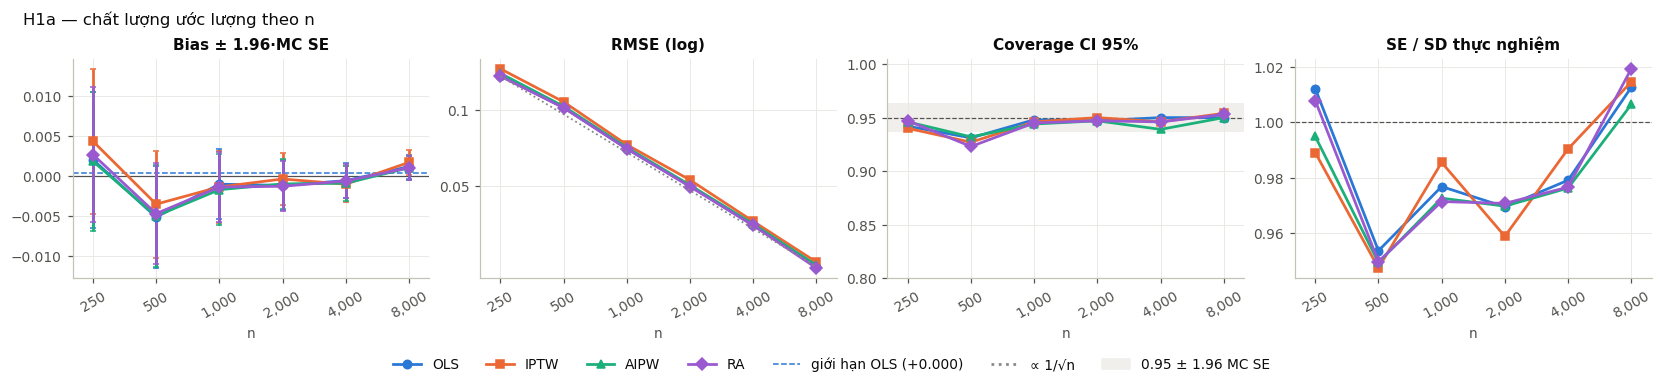

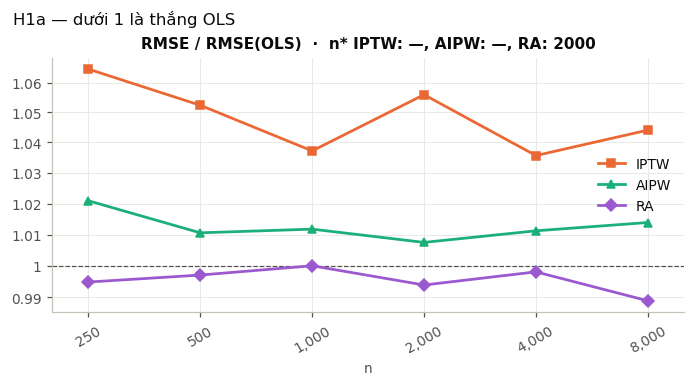

In [14]:
raw_H1a, diag_H1a = run_mc(simulate_H1a, design_linear, "H1a")
summary_H1a = report("H1a", raw_H1a, diag_H1a, LIMIT_H1a)

**Nhận xét H1a.**
- **Kỳ vọng:** có heterogeneity nhưng P(A=1) = 0.5, nên OLS vẫn không chệch.
- **Kết quả:** đúng như kỳ vọng. Bias của cả bốn trong ±0.005, coverage 0.92–0.95, RMSE gần như trùng nhau (n = 8000: 0.024–0.025). n* của RA bằng 2000 chỉ vì khác biệt RMSE ở chữ số thứ tư, không có ý nghĩa.
- **Giải thích:** e(1−e) đối xứng quanh X2 = 0, còn 0.5·X2 là hàm lẻ, nên trung bình có trọng số của OLS vẫn bằng 2. Riêng heterogeneity chưa đủ để OLS chệch.

## H1b — "Selection on gains": τ tăng theo X2 và chỉ 20% được điều trị

$$
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + 0.5X_2,\quad \mathbf{P(A=1) = 0.2},\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2,\qquad \boldsymbol{\tau(X) = 2 + 0.5X_2}
$$

Ghép đúng hai điều kiện mà **H0** và **H1a** tách riêng. Người có X2 cao vừa dễ được điều trị hơn, vừa hưởng lợi nhiều hơn.
Với P(A=1) = 0.2, vùng e ≈ 0.5 (nơi OLS dồn trọng số) nằm ở X2 cao.

**Kỳ vọng (pilot):** OLS ≈ **+0.14** và bias không giảm theo n, nên coverage OLS giảm dần. IPTW, AIPW, RA ≈ 0.
RA đúng vì τ(X) tuyến tính nên mô hình outcome riêng từng nhóm vẫn đúng dạng.

In [15]:
def dgp_H1b(n, rng):
    x1 = rng.normal(size=n)
    x2 = rng.normal(size=n)
    lin = 0.5*x1 + 0.5*x2
    mu0 = 0.5*x1 + 0.5*x2
    tau = TAU + 0.5*x2                          # KHÁC T0: tau(X) = 2 + 0.5 X2
    return {"X1": x1, "X2": x2}, lin, mu0, tau


GAMMA0_H1b = gamma0_for(dgp_H1b, target=0.2)    # KHÁC T0: P(A=1) = 0.2


def simulate_H1b(n, seed):
    return simulate(dgp_H1b, GAMMA0_H1b, n, seed)

In [16]:
_ = show_vs_base("H1b", {**FORMULA_T0, "τ(X)": "2 + 0.5·X2", "P(A=1) mục tiêu": "0.2"},
                 dgp_H1b, GAMMA0_H1b, target=0.2)

**H1b so với T0** (◆ = khác)

,T0,H1b,khác
X2,"N(0,1)","N(0,1)",
logit e(X),γ0 + 0.5·X1 + 0.5·X2,γ0 + 0.5·X1 + 0.5·X2,
μ0(X),0.5·X1 + 0.5·X2,0.5·X1 + 0.5·X2,
τ(X),2,2 + 0.5·X2,◆
P(A=1) mục tiêu,0.5,0.2,◆
γ0,-0.0012,-1.5270,◆
P(A=1) trên mẫu tham chiếu,0.5000,0.2000,◆
E[τ],2.0000,2.0004,◆
SD[τ],0.000,0.500,◆
ESS/n kỳ vọng (e thật),0.88,0.49,◆


Kiểm tra H1b: E[τ] ≈ 2, P(A=1) ≈ 0.2: PASS


In [17]:
LIMIT_H1b = large_sample_check(simulate_H1b, design_linear,
                               expected={"OLS": .141, "IPTW": .003, "AIPW": -.001, "RA": .001})

**Một mẫu n = 2,000,000** — SATE = 2.0001, P(A=1) = 0.199, ESS/n = 0.49

,ước lượng,bias,SE,kỳ vọng (pilot),lệch
method,,,,,
Naive,2.6487,0.6487,0.0025,NaN,NaN
OLS,2.1413,0.1413,0.0019,0.141,0.0003
IPTW,2.0006,0.0006,0.0025,0.003,-0.0024
AIPW,2.0013,0.0013,0.0021,-0.001,0.0023
RA,2.0015,0.0015,0.0020,0.001,0.0005


H1b: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 38s


**H1b: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                        rmse                      coverage                      se_sd_ratio                     
method    OLS   IPTW   AIPW     RA    OLS   IPTW   AIPW     RA      OLS   IPTW   AIPW     RA         OLS   IPTW   AIPW     RA
n                                                                                                                            
250     0.136  0.000 -0.009 -0.007  0.221  0.234  0.188  0.183    0.867  0.925  0.928  0.941       1.001  0.892  0.953  0.973
500     0.139  0.004 -0.001 -0.004  0.186  0.167  0.135  0.131    0.803  0.934  0.930  0.941       0.991  0.899  0.945  0.962
1000    0.141  0.005  0.001  0.001  0.167  0.118  0.094  0.092    0.621  0.935  0.948  0.950       0.988  0.930  0.967  0.971
2000    0.139  0.004  0.000 -0.001  0.151  0.079  0.064  0.063    0.396  0.940  0.961  0.955       1.030  0.983  1.015  1.009
4000    0.140 -0.000 -0.001 -0.000  0.146  0.056  0.046  0.045    0.107  0.939  0.939  0.937       1.007  0.985  0.995  0.998
8000    0.139  0.001 -0.000 -0.000  0.143  0.039  0.032  0.031    0.007  0.947  0.947  0.950       0.989  1.008  1.028  1.024

**Chẩn đoán trung bình qua rep** (ESS/n, trọng số lớn nhất, tỉ lệ lỗi fit PS)

,treated_rate,sate,e_min,e_max,max_weight,ess_ratio,ps_failure_rate,fail_AIPW,fail_IPTW,fail_Naive,fail_OLS,fail_RA
n,,,,,,,,,,,,
250,0.2,2.001,0.031,0.624,18.293,0.486,0.0,0.0,0.0,0.0,0.0,0.0
500,0.2,2.002,0.027,0.651,20.731,0.488,0.0,0.0,0.0,0.0,0.0,0.0
1000,0.2,2.000,0.022,0.683,23.587,0.487,0.0,0.0,0.0,0.0,0.0,0.0
2000,0.2,1.999,0.020,0.712,26.442,0.489,0.0,0.0,0.0,0.0,0.0,0.0
4000,0.2,2.000,0.017,0.734,29.998,0.488,0.0,0.0,0.0,0.0,0.0,0.0
8000,0.2,2.000,0.015,0.759,34.559,0.488,0.0,0.0,0.0,0.0,0.0,0.0


Bias OLS (MC) nằm trong 3 SE quanh giới hạn +0.1413 ở 6/6 giá trị n


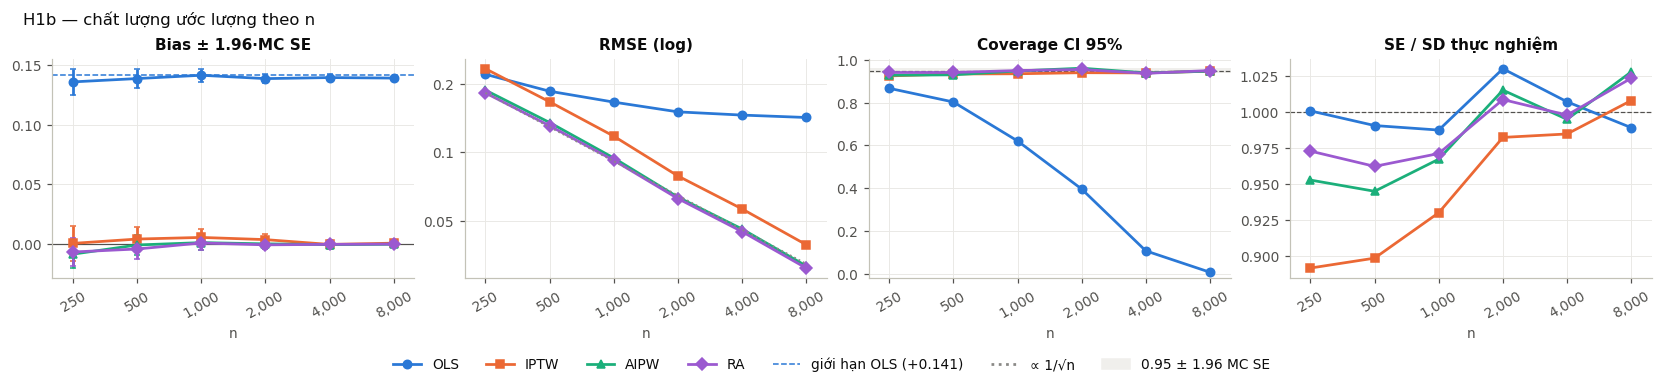

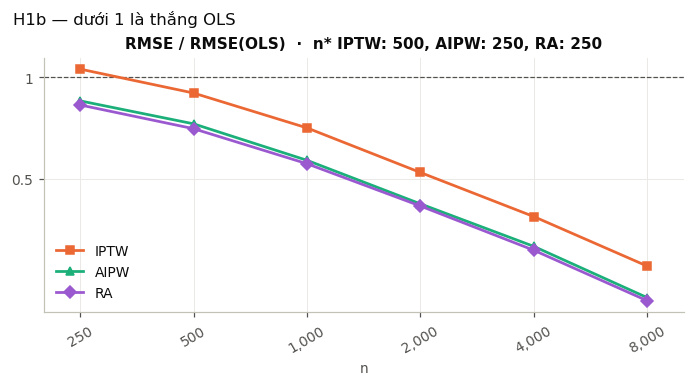

In [18]:
raw_H1b, diag_H1b = run_mc(simulate_H1b, design_linear, "H1b")
summary_H1b = report("H1b", raw_H1b, diag_H1b, LIMIT_H1b)

**Nhận xét H1b.**
- **Kỳ vọng:** OLS +0.14; IPTW, AIPW, RA ≈ 0.
- **Kết quả:** bias OLS +0.136 đến +0.141 ở mọi n, khớp giới hạn +0.141 trên mẫu lớn. Coverage OLS giảm từ 0.867 (n = 250) xuống **0.007** (n = 8000). IPTW, AIPW, RA có bias ≤ 0.01 và coverage 0.92–0.96. AIPW và RA có RMSE thấp hơn OLS **ngay từ n = 250** (0.188 và 0.183 so với 0.221); IPTW từ n = 500. Ở n = 8000, RMSE của OLS (0.143) gấp khoảng 4.5 lần AIPW (0.032).
- **Giải thích:** đây là trường hợp ghép cả hai điều kiện mà **H0** và **H1a** tách riêng. Với P(A=1) = 0.2, vùng e ≈ 0.5 nằm ở X2 cao, nơi τ lớn. OLS dồn trọng số vào đó nên ước lượng một trung bình lớn hơn ATE. RA sửa được vì τ(X) tuyến tính nên mô hình riêng từng nhóm đúng dạng. Lỗi của OLS ở đây là thiếu tương tác A×X, không phải vì hồi quy kém.

## H2 — Mức hiếm gần như ai cũng được điều trị và hưởng lợi nhiều hơn

X2 danh nghĩa 3 mức với xác suất (0.45, 0.45, 0.10), giống **T5** ở phần A nhưng nhẹ hơn (e ≈ 0.90 thay vì 0.98):

$$
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + \boldsymbol{\delta_r\,1[X_2 = 2]},\qquad
\mathbf{E[e \mid X_2 = 2] = 0.90},\quad P(A=1) = 0.5
$$

$$
\mu_0(X) = 0.5X_1 + \boldsymbol{h(X_2)},\quad h = \text{chuẩn hóa}(-1, 0, 1),\ \mathrm{Var}(h) = 0.25,\qquad
\boldsymbol{\tau(X) = 2 + 2\,(1[X_2 = 2] - 0.1)}
$$

Như vậy τ = 3.8 ở mức hiếm và 1.8 ở hai mức còn lại; E[τ] = 2. Phân tích dùng `dummy` cho X2, nên μ0 đúng dạng.

**Kỳ vọng (pilot):** OLS ≈ **−0.125**. Ở mức hiếm e(1−e) ≈ 0.09, nhỏ hơn nhiều so với ≈ 0.25 ở hai mức kia, nên OLS gần như bỏ qua hiệu ứng lớn ở mức hiếm.
IPTW, AIPW, RA ≈ 0 (RA đúng vì dummy bão hòa theo X2).

In [19]:
P_H2 = np.array([.45, .45, .10])


def standardize_effect(raw, probs):
    # Tâm hóa theo xác suất tổng thể; Var đóng góp = 0.25 (như phần A).
    raw, p = np.asarray(raw, float), np.asarray(probs, float)
    centered = raw - p @ raw
    return 0.5 * centered / np.sqrt(p @ centered**2)


H_H2 = standardize_effect([-1, 0, 1], P_H2)


def dgp_H2(n, rng, rare_shift=None):
    shift = RARE_SHIFT_H2 if rare_shift is None else rare_shift
    x1 = rng.normal(size=n)
    x2 = rng.choice(3, size=n, p=P_H2)          # KHÁC T0: X2 danh nghĩa 3 mức
    rare = (x2 == 2)
    lin = 0.5*x1 + shift*rare                   # KHÁC T0: X2 tác động lên A chỉ qua mức hiếm
    mu0 = 0.5*x1 + H_H2[x2]                     # KHÁC T0: hiệu ứng theo mức
    tau = TAU + 2.0*(rare - P_H2[2])            # KHÁC T0: mức hiếm có tau lớn hơn 2
    return {"X1": x1, "X2": x2}, lin, mu0, tau


# Hiệu chỉnh hai hằng số trên mẫu tham chiếu: E[e | mức hiếm] = 0.90 và P(A=1) = 0.5.
X_ref, lin_ref, _, _ = dgp_H2(N_REF, np.random.default_rng(12345), rare_shift=0.0)
rare_ref = X_ref["X2"] == 2
p_rare = rare_ref.mean()
GAMMA0_H2 = calibrate_gamma0(lin_ref[~rare_ref], (0.5 - p_rare*0.90)/(1 - p_rare))
RARE_SHIFT_H2 = calibrate_gamma0(lin_ref[rare_ref], 0.90) - GAMMA0_H2


def simulate_H2(n, seed):
    return simulate(dgp_H2, GAMMA0_H2, n, seed)


def design_H2(df):
    # Chặn + X1 + dummy của X2 (mức 0 làm tham chiếu).
    return np.column_stack([np.ones(len(df)), df.X1, df.X2 == 1, df.X2 == 2]).astype(float)


print(f"gamma0 = {GAMMA0_H2:.4f}, delta_r (dịch logit ở mức hiếm) = {RARE_SHIFT_H2:.4f}")

gamma0 = -0.1884, delta_r (dịch logit ở mức hiếm) = 2.4857


In [20]:
X_ref, lin_ref, _, tau_ref = show_vs_base(
    "H2", {**FORMULA_T0, "X2": "danh nghĩa 3 mức (.45, .45, .10)",
           "logit e(X)": "γ0 + 0.5·X1 + δr·1[X2=2]", "μ0(X)": "0.5·X1 + h(X2)",
           "τ(X)": "2 + 2·(1[X2=2] − 0.1)"},
    dgp_H2, GAMMA0_H2, target=0.5)
e_ref = expit(GAMMA0_H2 + lin_ref)
by_level = pd.DataFrame({"X2": X_ref["X2"], "e": e_ref, "τ": tau_ref, "w=e(1−e)": e_ref*(1-e_ref)}) \
             .groupby("X2").mean()
by_level["P(X2)"] = P_H2
display(Markdown("**Theo mức X2** (mẫu tham chiếu)"))
display(by_level.round(3))
assert abs(by_level.loc[2, "e"] - 0.90) < 1e-6
print("Kiểm tra H2: E[e | mức hiếm] = 0.90: PASS")

**H2 so với T0** (◆ = khác)

,T0,H2,khác
X2,"N(0,1)","danh nghĩa 3 mức (.45, .45, .10)",◆
logit e(X),γ0 + 0.5·X1 + 0.5·X2,γ0 + 0.5·X1 + δr·1[X2=2],◆
μ0(X),0.5·X1 + 0.5·X2,0.5·X1 + h(X2),◆
τ(X),2,2 + 2·(1[X2=2] − 0.1),◆
P(A=1) mục tiêu,0.5,0.5,
γ0,-0.0012,-0.1884,◆
P(A=1) trên mẫu tham chiếu,0.5000,0.5000,
E[τ],2.0000,1.9988,◆
SD[τ],0.000,0.598,◆
ESS/n kỳ vọng (e thật),0.88,0.77,◆


Kiểm tra H2: E[τ] ≈ 2, P(A=1) ≈ 0.5: PASS


**Theo mức X2** (mẫu tham chiếu)

,e,τ,w=e(1−e),P(X2)
X2,,,,
0,0.456,1.8,0.234,0.45
1,0.456,1.8,0.234,0.45
2,0.900,3.8,0.088,0.10


Kiểm tra H2: E[e | mức hiếm] = 0.90: PASS


In [21]:
LIMIT_H2 = large_sample_check(simulate_H2, design_H2,
                              expected={"OLS": -.125, "IPTW": -.002, "AIPW": -.004})

**Một mẫu n = 2,000,000** — SATE = 2.0002, P(A=1) = 0.500, ESS/n = 0.77

,ước lượng,bias,SE,kỳ vọng (pilot),lệch
method,,,,,
Naive,2.5649,0.5649,0.0020,NaN,NaN
OLS,1.8786,-0.1214,0.0016,-0.125,0.0036
IPTW,2.0016,0.0016,0.0018,-0.002,0.0036
AIPW,2.0021,0.0021,0.0017,-0.004,0.0061
RA,2.0020,0.0020,0.0016,NaN,NaN


H2: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 44s


**H2: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                        rmse                      coverage                      se_sd_ratio                     
method    OLS   IPTW   AIPW     RA    OLS   IPTW   AIPW     RA      OLS   IPTW   AIPW     RA         OLS   IPTW   AIPW     RA
n                                                                                                                            
250    -0.122  0.010  0.007  0.008  0.189  0.174  0.156  0.155    0.844  0.910  0.921  0.918       0.978  0.845  0.892  0.896
500    -0.117  0.008  0.005  0.006  0.153  0.111  0.103  0.103    0.768  0.942  0.952  0.952       1.016  0.976  0.994  0.991
1000   -0.122  0.000  0.001  0.001  0.142  0.084  0.078  0.076    0.595  0.940  0.937  0.938       0.974  0.941  0.958  0.953
2000   -0.124  0.002  0.001  0.001  0.133  0.058  0.054  0.053    0.312  0.944  0.944  0.947       0.991  0.968  0.973  0.966
4000   -0.122  0.001  0.001  0.001  0.128  0.041  0.039  0.038    0.081  0.942  0.937  0.936       0.966  0.967  0.955  0.956
8000   -0.122  0.000  0.000  0.000  0.124  0.028  0.026  0.025    0.002  0.954  0.955  0.954       0.996  0.998  1.026  1.017

**Chẩn đoán trung bình qua rep** (ESS/n, trọng số lớn nhất, tỉ lệ lỗi fit PS)

,treated_rate,sate,e_min,e_max,max_weight,ess_ratio,ps_failure_rate,fail_AIPW,fail_IPTW,fail_Naive,fail_OLS,fail_RA
n,,,,,,,,,,,,
250,0.501,1.999,0.171,0.958,14.467,0.761,0.098,0.098,0.098,0.0,0.0,0.098
500,0.500,2.000,0.156,0.967,18.205,0.751,0.002,0.002,0.002,0.0,0.0,0.002
1000,0.500,2.000,0.144,0.970,20.212,0.757,0.000,0.000,0.000,0.0,0.0,0.000
2000,0.500,2.000,0.131,0.974,22.846,0.761,0.000,0.000,0.000,0.0,0.0,0.000
4000,0.500,2.000,0.122,0.977,25.223,0.765,0.000,0.000,0.000,0.0,0.0,0.000
8000,0.500,2.000,0.112,0.979,28.559,0.766,0.000,0.000,0.000,0.0,0.0,0.000


Bias OLS (MC) nằm trong 3 SE quanh giới hạn -0.1214 ở 6/6 giá trị n


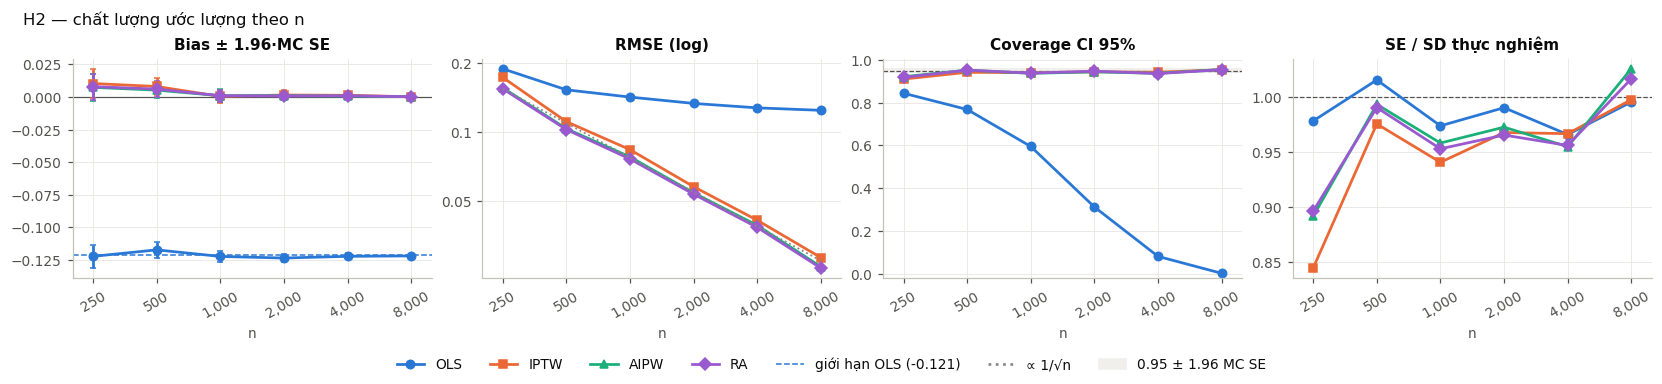

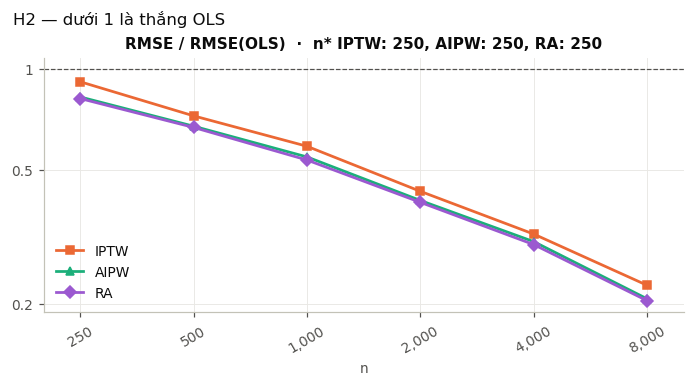

In [22]:
raw_H2, diag_H2 = run_mc(simulate_H2, design_H2, "H2")
summary_H2 = report("H2", raw_H2, diag_H2, LIMIT_H2)

**Nhận xét H2.**
- **Kỳ vọng:** OLS −0.125; IPTW, AIPW, RA ≈ 0.
- **Kết quả:** bias OLS −0.117 đến −0.124, khớp giới hạn −0.121; coverage OLS giảm từ 0.844 xuống **0.002**. IPTW, AIPW, RA có bias ≤ 0.01 và đều thắng OLS về RMSE từ n = 250. Ở n = 250, **9.8%** số rep lỗi fit PS: mức hiếm chỉ có khoảng 25 người, trong đó khoảng 2–3 control, nên có rep không có control nào. Các phương pháp cần PS hoặc mô hình riêng từng nhóm (IPTW, AIPW, RA) mất các rep đó. Từ n = 500 tỉ lệ lỗi gần 0.
- **Giải thích:** trong mức hiếm e(1−e) ≈ 0.09, còn ở hai mức kia ≈ 0.23. OLS vì vậy gần như bỏ qua hiệu ứng τ = 3.8 của mức hiếm. Khác **T5** của phần A (τ đồng nhất, OLS không chệch): khi overlap kém đi kèm heterogeneity, chính trọng số ngầm của OLS gây chệch.

## H3 — τ phi tuyến theo X2 (hàm chẵn)

$$
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + 0.5X_2,\quad P(A=1) = 0.5,\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2,\qquad \boldsymbol{\tau(X) = 2 + \tfrac{X_2^2 - 1}{\sqrt 2}}
$$

SD[τ] = 1. Ngược với **H1a**, ở đây τ lớn ở *cả hai* đuôi của X2, đúng nơi e gần 0 hoặc 1 và OLS cho trọng số nhỏ.

**Kỳ vọng (pilot):** OLS ≈ **−0.075**. **RA cũng ≈ −0.075**: mô hình outcome riêng từng nhóm tuyến tính theo X2 nên không bắt được X2².
Chỉ IPTW và AIPW ≈ 0 vì PS đúng. Đây là kịch bản tách được giá trị riêng của AIPW (double robust) so với hồi quy thuần túy.

In [23]:
def dgp_H3(n, rng):
    x1 = rng.normal(size=n)
    x2 = rng.normal(size=n)
    lin = 0.5*x1 + 0.5*x2
    mu0 = 0.5*x1 + 0.5*x2
    tau = TAU + (x2**2 - 1)/np.sqrt(2)          # KHÁC T0: tau(X) = 2 + (X2^2 - 1)/sqrt(2)
    return {"X1": x1, "X2": x2}, lin, mu0, tau


GAMMA0_H3 = gamma0_for(dgp_H3, target=0.5)


def simulate_H3(n, seed):
    return simulate(dgp_H3, GAMMA0_H3, n, seed)

In [24]:
_ = show_vs_base("H3", {**FORMULA_T0, "τ(X)": "2 + (X2² − 1)/√2"}, dgp_H3, GAMMA0_H3, target=0.5)

**H3 so với T0** (◆ = khác)

,T0,H3,khác
X2,"N(0,1)","N(0,1)",
logit e(X),γ0 + 0.5·X1 + 0.5·X2,γ0 + 0.5·X1 + 0.5·X2,
μ0(X),0.5·X1 + 0.5·X2,0.5·X1 + 0.5·X2,
τ(X),2,2 + (X2² − 1)/√2,◆
P(A=1) mục tiêu,0.5,0.5,
γ0,-0.0012,-0.0012,
P(A=1) trên mẫu tham chiếu,0.5000,0.5000,
E[τ],2.0000,2.0006,◆
SD[τ],0.000,1.001,◆
ESS/n kỳ vọng (e thật),0.88,0.88,


Kiểm tra H3: E[τ] ≈ 2, P(A=1) ≈ 0.5: PASS


In [25]:
LIMIT_H3 = large_sample_check(simulate_H3, design_linear,
                              expected={"OLS": -.075, "IPTW": -.003, "AIPW": -.002, "RA": -.075})

**Một mẫu n = 2,000,000** — SATE = 2.0010, P(A=1) = 0.500, ESS/n = 0.88

,ước lượng,bias,SE,kỳ vọng (pilot),lệch
method,,,,,
Naive,2.4499,0.4499,0.0020,NaN,NaN
OLS,1.9290,-0.0710,0.0018,-0.075,0.0040
IPTW,2.0009,0.0009,0.0019,-0.003,0.0039
AIPW,2.0015,0.0015,0.0021,-0.002,0.0035
RA,1.9289,-0.0711,0.0018,-0.075,0.0039


H3: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 37s


**H3: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                        rmse                      coverage                      se_sd_ratio                     
method    OLS   IPTW   AIPW     RA    OLS   IPTW   AIPW     RA      OLS   IPTW   AIPW     RA         OLS   IPTW   AIPW     RA
n                                                                                                                            
250    -0.073  0.008  0.004 -0.074  0.174  0.176  0.196  0.176    0.922  0.944  0.945  0.921       1.033  0.960  0.930  1.023
500    -0.071  0.005  0.002 -0.071  0.134  0.119  0.126  0.136    0.897  0.950  0.951  0.896       1.008  1.003  1.017  1.004
1000   -0.074 -0.001 -0.003 -0.074  0.110  0.085  0.087  0.111    0.842  0.950  0.959  0.843       0.998  0.999  1.043  0.999
2000   -0.074 -0.001 -0.001 -0.074  0.094  0.062  0.065  0.095    0.749  0.939  0.955  0.750       0.968  0.963  0.992  0.969
4000   -0.073 -0.001 -0.001 -0.073  0.084  0.043  0.044  0.084    0.547  0.951  0.957  0.557       0.993  0.997  1.028  0.992
8000   -0.073 -0.001 -0.001 -0.073  0.078  0.031  0.032  0.079    0.288  0.942  0.947  0.299       0.977  0.972  1.002  0.974

**Chẩn đoán trung bình qua rep** (ESS/n, trọng số lớn nhất, tỉ lệ lỗi fit PS)

,treated_rate,sate,e_min,e_max,max_weight,ess_ratio,ps_failure_rate,fail_AIPW,fail_IPTW,fail_Naive,fail_OLS,fail_RA
n,,,,,,,,,,,,
250,0.500,2.000,0.123,0.878,7.170,0.858,0.0,0.0,0.0,0.0,0.0,0.0
500,0.500,2.003,0.106,0.893,7.702,0.867,0.0,0.0,0.0,0.0,0.0,0.0
1000,0.499,2.001,0.094,0.904,8.344,0.872,0.0,0.0,0.0,0.0,0.0,0.0
2000,0.500,2.000,0.083,0.919,9.376,0.874,0.0,0.0,0.0,0.0,0.0,0.0
4000,0.500,2.000,0.074,0.926,10.473,0.874,0.0,0.0,0.0,0.0,0.0,0.0
8000,0.500,2.000,0.065,0.936,11.621,0.875,0.0,0.0,0.0,0.0,0.0,0.0


Bias OLS (MC) nằm trong 3 SE quanh giới hạn -0.0710 ở 6/6 giá trị n


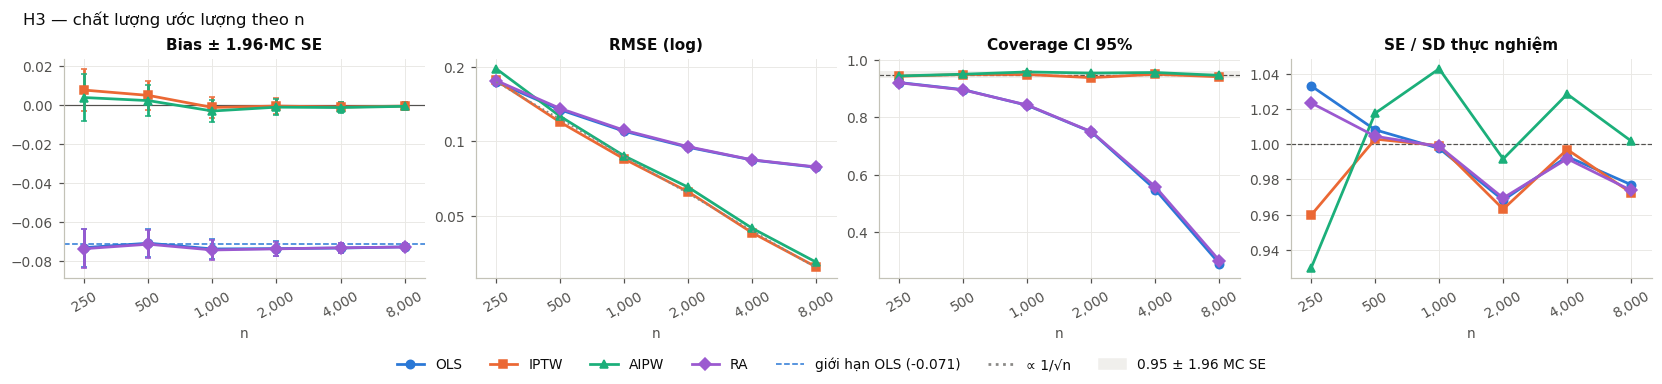

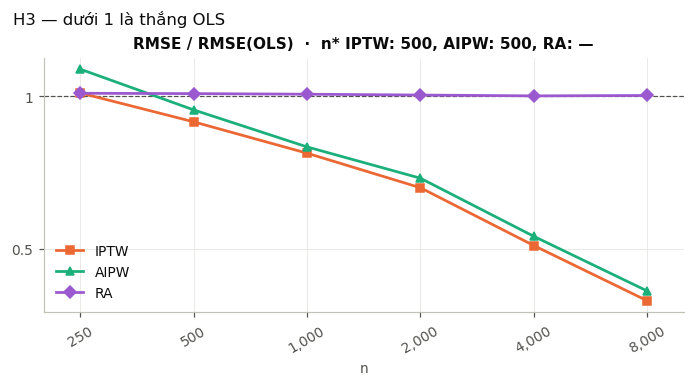

In [26]:
raw_H3, diag_H3 = run_mc(simulate_H3, design_linear, "H3")
summary_H3 = report("H3", raw_H3, diag_H3, LIMIT_H3)

**Nhận xét H3.**
- **Kỳ vọng:** OLS và RA ≈ −0.075; IPTW, AIPW ≈ 0.
- **Kết quả:** OLS và **RA cùng chệch** −0.071 đến −0.074 ở mọi n; coverage của cả hai giảm từ 0.92 xuống khoảng 0.29. IPTW, AIPW có bias ≤ 0.008, coverage 0.94–0.96. Ở n = 250 OLS còn ngang (0.174 so với 0.176 và 0.196); từ n = 500, IPTW và AIPW thắng. Ở n = 8000, RMSE của OLS gấp khoảng 2.5 lần.
- **Giải thích:** τ lớn ở hai đuôi X2, đúng nơi e gần 0/1 và OLS cho trọng số nhỏ. Thêm tương tác tuyến tính (RA) không đủ, vì mô hình riêng từng nhóm vẫn tuyến tính theo X2, không có X2². Chỉ các phương pháp dựa vào PS đúng mới không chệch. Đây là kịch bản cho thấy giá trị **double robust** của AIPW so với hồi quy thuần túy.

## M1a — μ0 có thành phần bậc ba, selection như T0 (γ = 0.5)

$$
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + 0.5X_2,\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2 + \boldsymbol{\kappa\,\mathrm{He}_3(X_2)},\quad
\mathrm{He}_3(x) = \frac{x^3 - 3x}{\sqrt 6},\ \kappa = 1,\qquad \tau(X) = 2
$$

He3 (đa thức Hermite bậc 3, chuẩn hóa) có trung bình 0, phương sai 1 và **trực giao với X2**. Phần tuyến tính của μ0 vì vậy giữ nguyên như T0, chỉ thêm một thành phần phi tuyến mà design tuyến tính không bắt được.
**M1a/b/c** chỉ khác độ mạnh selection γ1 = γ2 ∈ {0.5, 1.0, 1.5}.

**Kỳ vọng:** với γ = 0.5, PS gần như tuyến tính nên OLS (và RA) vẫn gần không chệch dù μ0 sai dạng (ý 3 ở đầu notebook).

In [27]:
KAPPA_M1 = 1.0


def he3(x):
    return (x**3 - 3*x)/np.sqrt(6)


def dgp_M1(n, rng, gamma):
    x1 = rng.normal(size=n)
    x2 = rng.normal(size=n)
    lin = gamma*x1 + gamma*x2                   # KHÁC T0 (ở M1b/c): gamma1 = gamma2 = gamma
    mu0 = 0.5*x1 + 0.5*x2 + KAPPA_M1*he3(x2)    # KHÁC T0: thêm kappa * He3(X2)
    tau = np.full(n, TAU)
    return {"X1": x1, "X2": x2}, lin, mu0, tau


def dgp_M1a(n, rng):
    return dgp_M1(n, rng, gamma=0.5)


GAMMA0_M1a = gamma0_for(dgp_M1a, target=0.5)


def simulate_M1a(n, seed):
    return simulate(dgp_M1a, GAMMA0_M1a, n, seed)

In [28]:
FORMULA_M1a = {**FORMULA_T0, "μ0(X)": "0.5·X1 + 0.5·X2 + He3(X2)"}
X_ref, *_ = show_vs_base("M1a", FORMULA_M1a, dgp_M1a, GAMMA0_M1a, target=0.5)
h = he3(X_ref["X2"])
print(f"He3 trên mẫu tham chiếu: mean = {h.mean():+.4f}, var = {h.var():.4f}, "
      f"corr với X2 = {np.corrcoef(h, X_ref['X2'])[0, 1]:+.4f}")
assert abs(h.mean()) < .02 and abs(h.var() - 1) < .05 and abs(np.corrcoef(h, X_ref["X2"])[0, 1]) < .02
print("Kiểm tra He3: mean 0, var 1, trực giao X2: PASS")

**M1a so với T0** (◆ = khác)

,T0,M1a,khác
X2,"N(0,1)","N(0,1)",
logit e(X),γ0 + 0.5·X1 + 0.5·X2,γ0 + 0.5·X1 + 0.5·X2,
μ0(X),0.5·X1 + 0.5·X2,0.5·X1 + 0.5·X2 + He3(X2),◆
τ(X),2,2,
P(A=1) mục tiêu,0.5,0.5,
γ0,-0.0012,-0.0012,
P(A=1) trên mẫu tham chiếu,0.5000,0.5000,
E[τ],2.0000,2.0000,
SD[τ],0.000,0.000,
ESS/n kỳ vọng (e thật),0.88,0.88,


Kiểm tra M1a: E[τ] ≈ 2, P(A=1) ≈ 0.5: PASS
He3 trên mẫu tham chiếu: mean = +0.0012, var = 0.9962, corr với X2 = +0.0017
Kiểm tra He3: mean 0, var 1, trực giao X2: PASS


In [29]:
LIMIT_M1a = large_sample_check(simulate_M1a, design_linear,
                               expected={"IPTW": 0., "AIPW": 0.})

**Một mẫu n = 2,000,000** — SATE = 2.0000, P(A=1) = 0.500, ESS/n = 0.88

,ước lượng,bias,SE,kỳ vọng (pilot),lệch
method,,,,,
Naive,2.4338,0.4338,0.0022,NaN,NaN
OLS,1.9823,-0.0177,0.0020,NaN,NaN
IPTW,2.0008,0.0008,0.0025,0.0,0.0008
AIPW,2.0013,0.0013,0.0024,0.0,0.0013
RA,1.9823,-0.0177,0.0020,NaN,NaN


M1a: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 38s


**M1a: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                        rmse                      coverage                      se_sd_ratio                     
method    OLS   IPTW   AIPW     RA    OLS   IPTW   AIPW     RA      OLS   IPTW   AIPW     RA         OLS   IPTW   AIPW     RA
n                                                                                                                            
250    -0.018  0.008  0.010 -0.014  0.175  0.220  0.206  0.175    0.951  0.934  0.941  0.949       1.003  0.908  0.947  0.996
500    -0.013  0.010  0.011 -0.011  0.124  0.163  0.154  0.123    0.942  0.942  0.940  0.945       1.012  0.898  0.926  1.010
1000   -0.020  0.001  0.001 -0.019  0.093  0.114  0.108  0.093    0.948  0.936  0.939  0.946       0.973  0.932  0.947  0.971
2000   -0.022 -0.002 -0.002 -0.021  0.068  0.082  0.078  0.068    0.938  0.940  0.947  0.940       0.976  0.931  0.938  0.975
4000   -0.020 -0.001 -0.001 -0.020  0.049  0.056  0.053  0.049    0.928  0.945  0.950  0.926       0.996  0.981  0.985  0.994
8000   -0.019 -0.001 -0.001 -0.019  0.037  0.039  0.037  0.037    0.911  0.955  0.952  0.910       1.007  0.993  0.995  1.008

**Chẩn đoán trung bình qua rep** (ESS/n, trọng số lớn nhất, tỉ lệ lỗi fit PS)

,treated_rate,sate,e_min,e_max,max_weight,ess_ratio,ps_failure_rate,fail_AIPW,fail_IPTW,fail_Naive,fail_OLS,fail_RA
n,,,,,,,,,,,,
250,0.500,2.0,0.122,0.877,7.062,0.861,0.0,0.0,0.0,0.0,0.0,0.0
500,0.500,2.0,0.107,0.893,7.737,0.866,0.0,0.0,0.0,0.0,0.0,0.0
1000,0.500,2.0,0.094,0.906,8.511,0.871,0.0,0.0,0.0,0.0,0.0,0.0
2000,0.500,2.0,0.083,0.916,9.388,0.873,0.0,0.0,0.0,0.0,0.0,0.0
4000,0.499,2.0,0.073,0.926,10.540,0.875,0.0,0.0,0.0,0.0,0.0,0.0
8000,0.500,2.0,0.065,0.934,11.654,0.875,0.0,0.0,0.0,0.0,0.0,0.0


Bias OLS (MC) nằm trong 3 SE quanh giới hạn -0.0177 ở 6/6 giá trị n


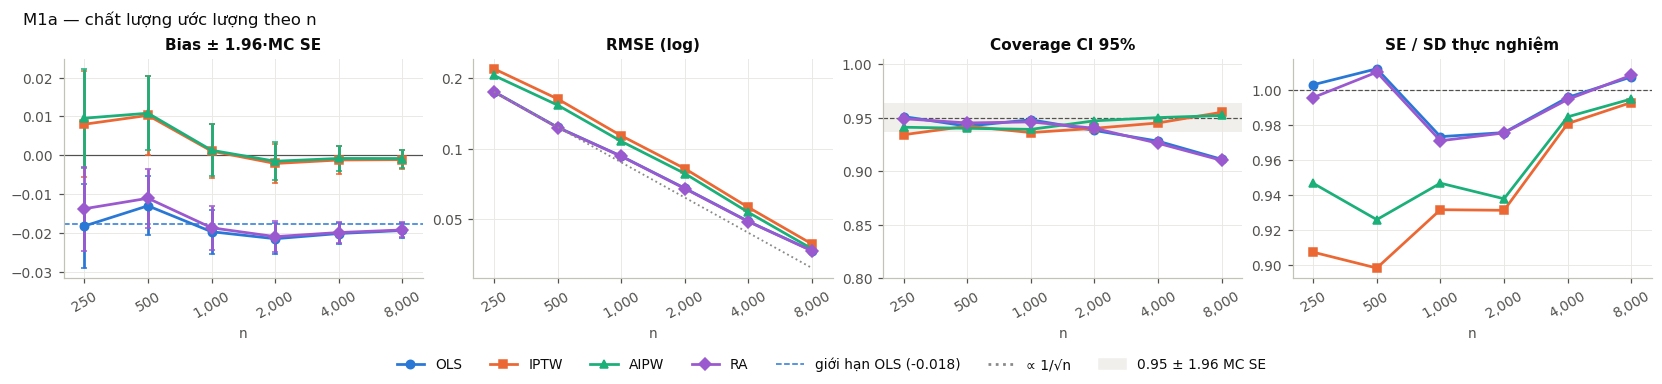

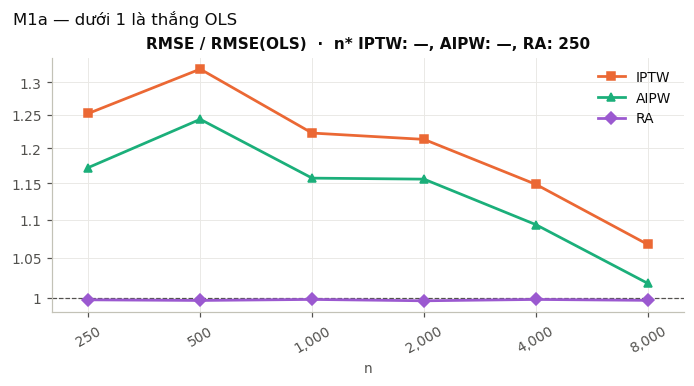

In [30]:
raw_M1a, diag_M1a = run_mc(simulate_M1a, design_linear, "M1a")
summary_M1a = report("M1a", raw_M1a, diag_M1a, LIMIT_M1a)

**Nhận xét M1a.**
- **Kỳ vọng:** μ0 sai dạng nhưng PS gần tuyến tính (γ = 0.5), nên OLS gần không chệch.
- **Kết quả:** OLS và RA chệch nhẹ −0.02 (giới hạn −0.018), coverage giảm từ 0.95 xuống 0.91 ở n = 8000. IPTW, AIPW ≈ 0. Về RMSE OLS vẫn thắng hoặc hòa ở mọi n (n = 8000: 0.037 cả hai), vì ESS/n = 0.87 và bias nhỏ.
- **Giải thích:** đúng với ý 3 ở đầu notebook. Với γ = 0.5, E[A|X] gần tuyến tính nên OLS gần như double robust. Phần chệch còn lại nhỏ, chỉ thấy rõ qua coverage khi n lớn.

## M1b — μ0 bậc ba, selection mạnh hơn (γ = 1.0)

$$
\operatorname{logit} e(X) = \gamma_0 + \mathbf{1.0}\,X_1 + \mathbf{1.0}\,X_2,\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2 + \mathrm{He}_3(X_2),\qquad \tau(X) = 2
$$

**Kỳ vọng (pilot):** logistic cong rõ hơn trên miền của X, nên E[A|X] không còn gần tuyến tính và OLS mất tính "gần double robust".
OLS, RA ≈ **−0.09**; IPTW, AIPW ≈ 0 nhưng ESS/n chỉ còn khoảng 0.53.

In [31]:
def dgp_M1b(n, rng):
    return dgp_M1(n, rng, gamma=1.0)            # KHÁC M1a: gamma = 1.0


GAMMA0_M1b = gamma0_for(dgp_M1b, target=0.5)


def simulate_M1b(n, seed):
    return simulate(dgp_M1b, GAMMA0_M1b, n, seed)

In [32]:
_ = show_vs_base("M1b", {**FORMULA_M1a, "logit e(X)": "γ0 + 1.0·X1 + 1.0·X2"}, dgp_M1b, GAMMA0_M1b,
                 target=0.5, base="M1a", base_formulas=FORMULA_M1a, base_dgp=dgp_M1a,
                 base_gamma0=GAMMA0_M1a)

**M1b so với M1a** (◆ = khác)

,M1a,M1b,khác
X2,"N(0,1)","N(0,1)",
logit e(X),γ0 + 0.5·X1 + 0.5·X2,γ0 + 1.0·X1 + 1.0·X2,◆
μ0(X),0.5·X1 + 0.5·X2 + He3(X2),0.5·X1 + 0.5·X2 + He3(X2),
τ(X),2,2,
P(A=1) mục tiêu,0.5,0.5,
γ0,-0.0012,-0.0021,◆
P(A=1) trên mẫu tham chiếu,0.5000,0.5000,
E[τ],2.0000,2.0000,
SD[τ],0.000,0.000,
ESS/n kỳ vọng (e thật),0.88,0.54,◆


Kiểm tra M1b: E[τ] ≈ 2, P(A=1) ≈ 0.5: PASS


In [33]:
LIMIT_M1b = large_sample_check(simulate_M1b, design_linear,
                               expected={"OLS": -.088, "IPTW": 0., "AIPW": 0., "RA": -.088})

**Một mẫu n = 2,000,000** — SATE = 2.0000, P(A=1) = 0.500, ESS/n = 0.53

,ước lượng,bias,SE,kỳ vọng (pilot),lệch
method,,,,,
Naive,2.6604,0.6604,0.0022,NaN,NaN
OLS,1.9089,-0.0911,0.0021,-0.088,-0.0031
IPTW,1.9975,-0.0025,0.0053,0.000,-0.0025
AIPW,1.9989,-0.0011,0.0045,0.000,-0.0011
RA,1.9089,-0.0911,0.0021,-0.088,-0.0031


M1b: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 40s


**M1b: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                        rmse                      coverage                      se_sd_ratio                     
method    OLS   IPTW   AIPW     RA    OLS   IPTW   AIPW     RA      OLS   IPTW   AIPW     RA         OLS   IPTW   AIPW     RA
n                                                                                                                            
250    -0.099  0.019  0.008 -0.091  0.221  0.352  0.307  0.217    0.923  0.884  0.937  0.926       0.954  0.699  0.801  0.949
500    -0.091  0.017  0.008 -0.088  0.161  0.262  0.227  0.158    0.914  0.884  0.943  0.919       1.007  0.743  0.815  1.008
1000   -0.092  0.004  0.002 -0.091  0.132  0.183  0.159  0.131    0.856  0.912  0.944  0.857       1.001  0.845  0.877  0.998
2000   -0.088  0.018  0.012 -0.087  0.112  0.139  0.121  0.111    0.742  0.896  0.928  0.749       0.972  0.805  0.819  0.971
4000   -0.088  0.004  0.003 -0.088  0.099  0.116  0.100  0.099    0.553  0.900  0.923  0.559       1.057  0.773  0.781  1.054
8000   -0.090  0.002  0.001 -0.089  0.096  0.083  0.071  0.096    0.242  0.899  0.929  0.236       1.003  0.806  0.817  1.002

**Chẩn đoán trung bình qua rep** (ESS/n, trọng số lớn nhất, tỉ lệ lỗi fit PS)

,treated_rate,sate,e_min,e_max,max_weight,ess_ratio,ps_failure_rate,fail_AIPW,fail_IPTW,fail_Naive,fail_OLS,fail_RA
n,,,,,,,,,,,,
250,0.499,2.0,0.021,0.979,19.369,0.577,0.0,0.0,0.0,0.0,0.0,0.0
500,0.500,2.0,0.016,0.984,24.097,0.571,0.0,0.0,0.0,0.0,0.0,0.0
1000,0.500,2.0,0.011,0.989,30.327,0.557,0.0,0.0,0.0,0.0,0.0,0.0
2000,0.499,2.0,0.009,0.991,35.580,0.559,0.0,0.0,0.0,0.0,0.0,0.0
4000,0.500,2.0,0.007,0.993,46.360,0.548,0.0,0.0,0.0,0.0,0.0,0.0
8000,0.500,2.0,0.005,0.995,57.445,0.544,0.0,0.0,0.0,0.0,0.0,0.0


Bias OLS (MC) nằm trong 3 SE quanh giới hạn -0.0911 ở 6/6 giá trị n


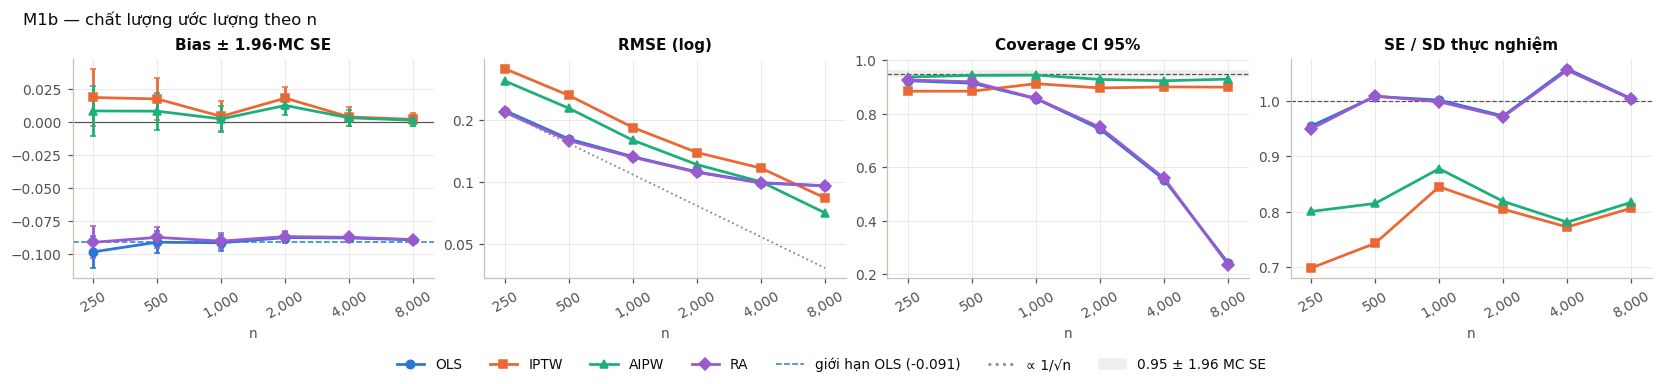

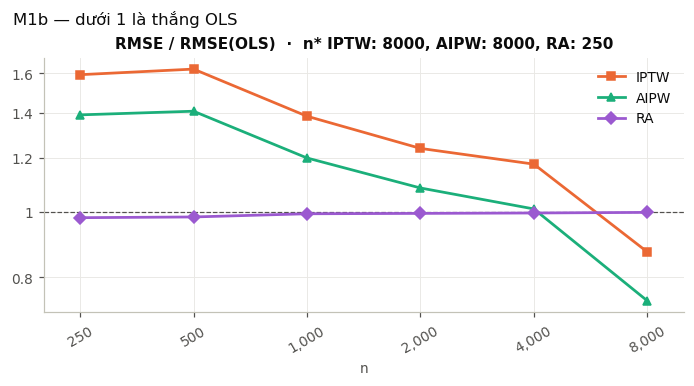

In [34]:
raw_M1b, diag_M1b = run_mc(simulate_M1b, design_linear, "M1b")
summary_M1b = report("M1b", raw_M1b, diag_M1b, LIMIT_M1b)

**Nhận xét M1b.**
- **Kỳ vọng:** OLS, RA ≈ −0.09; IPTW, AIPW ≈ 0 nhưng ESS/n còn khoảng 0.55.
- **Kết quả:** OLS và RA −0.087 đến −0.099, coverage giảm xuống 0.24 ở n = 8000. AIPW gần không chệch (≤ 0.012) nhưng **SE/SD chỉ 0.78–0.88**, nên coverage dừng ở 0.92–0.94. IPTW tệ hơn: SE/SD khoảng 0.75, coverage khoảng 0.89. Về RMSE, AIPW và IPTW chỉ thắng OLS ở **n = 8000** (0.071 so với 0.096); ở n = 4000 là hòa.
- **Giải thích:** γ = 1 làm logistic cong rõ, nên OLS mất tính gần double robust. Đổi lại, trọng số lớn hơn (max weight trung bình 19 → 57) làm phân phối của IPTW/AIPW có đuôi dày. SD thực nghiệm bị vài rep cực đoan kéo lên, còn SE dựa trên IF thì không phản ánh hết.

## M1c — μ0 bậc ba, selection rất mạnh (γ = 1.5)

$$
\operatorname{logit} e(X) = \gamma_0 + \mathbf{1.5}\,X_1 + \mathbf{1.5}\,X_2,\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2 + \mathrm{He}_3(X_2),\qquad \tau(X) = 2
$$

**Kỳ vọng (pilot):** OLS, RA ≈ **−0.18**. IPTW, AIPW ≈ 0 nhưng ESS/n ≈ 0.20 và ê sát 0/1, nên ở n nhỏ phương sai lớn và có thể có lỗi fit (không clip, giống **T5**).
Đây là chỗ đánh đổi bias–phương sai rõ nhất: ở n nhỏ OLS có thể vẫn có RMSE thấp hơn, n lớn thì ngược lại.

In [35]:
def dgp_M1c(n, rng):
    return dgp_M1(n, rng, gamma=1.5)            # KHÁC M1a: gamma = 1.5


GAMMA0_M1c = gamma0_for(dgp_M1c, target=0.5)


def simulate_M1c(n, seed):
    return simulate(dgp_M1c, GAMMA0_M1c, n, seed)

In [36]:
_ = show_vs_base("M1c", {**FORMULA_M1a, "logit e(X)": "γ0 + 1.5·X1 + 1.5·X2"}, dgp_M1c, GAMMA0_M1c,
                 target=0.5, base="M1a", base_formulas=FORMULA_M1a, base_dgp=dgp_M1a,
                 base_gamma0=GAMMA0_M1a)

**M1c so với M1a** (◆ = khác)

,M1a,M1c,khác
X2,"N(0,1)","N(0,1)",
logit e(X),γ0 + 0.5·X1 + 0.5·X2,γ0 + 1.5·X1 + 1.5·X2,◆
μ0(X),0.5·X1 + 0.5·X2 + He3(X2),0.5·X1 + 0.5·X2 + He3(X2),
τ(X),2,2,
P(A=1) mục tiêu,0.5,0.5,
γ0,-0.0012,-0.0031,◆
P(A=1) trên mẫu tham chiếu,0.5000,0.5000,
E[τ],2.0000,2.0000,
SD[τ],0.000,0.000,
ESS/n kỳ vọng (e thật),0.88,0.19,◆


Kiểm tra M1c: E[τ] ≈ 2, P(A=1) ≈ 0.5: PASS


In [37]:
LIMIT_M1c = large_sample_check(simulate_M1c, design_linear,
                               expected={"OLS": -.178, "IPTW": 0., "AIPW": 0., "RA": -.178})

**Một mẫu n = 2,000,000** — SATE = 2.0000, P(A=1) = 0.500, ESS/n = 0.22

,ước lượng,bias,SE,kỳ vọng (pilot),lệch
method,,,,,
Naive,2.7629,0.7629,0.0022,NaN,NaN
OLS,1.8132,-0.1868,0.0024,-0.178,-0.0088
IPTW,2.0127,0.0127,0.0081,0.000,0.0127
AIPW,2.0086,0.0086,0.0062,0.000,0.0086
RA,1.8133,-0.1867,0.0024,-0.178,-0.0087


M1c: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 40s


**M1c: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                        rmse                      coverage                      se_sd_ratio                     
method    OLS   IPTW   AIPW     RA    OLS   IPTW   AIPW     RA      OLS   IPTW   AIPW     RA         OLS   IPTW   AIPW     RA
n                                                                                                                            
250    -0.172  0.100  0.030 -0.162  0.274  0.496  0.599  0.266    0.877  0.785  0.937  0.888       0.993  0.530  0.518  0.986
500    -0.174  0.062  0.026 -0.169  0.228  0.411  0.413  0.225    0.814  0.788  0.954  0.820       1.027  0.553  0.586  1.014
1000   -0.177  0.032  0.012 -0.175  0.209  0.343  0.319  0.207    0.617  0.784  0.940  0.624       0.973  0.584  0.624  0.964
2000   -0.181  0.024 -0.003 -0.180  0.197  0.293  0.279  0.196    0.330  0.787  0.917  0.334       0.987  0.564  0.554  0.982
4000   -0.183  0.015  0.007 -0.182  0.191  0.212  0.174  0.190    0.072  0.797  0.915  0.073       1.008  0.641  0.672  1.004
8000   -0.180 -0.005 -0.004 -0.180  0.184  0.194  0.155  0.184    0.002  0.808  0.901  0.002       1.040  0.615  0.627  1.040

**Chẩn đoán trung bình qua rep** (ESS/n, trọng số lớn nhất, tỉ lệ lỗi fit PS)

,treated_rate,sate,e_min,e_max,max_weight,ess_ratio,ps_failure_rate,fail_AIPW,fail_IPTW,fail_Naive,fail_OLS,fail_RA
n,,,,,,,,,,,,
250,0.5,2.0,0.004,0.996,36.612,0.384,0.0,0.0,0.0,0.0,0.0,0.0
500,0.5,2.0,0.002,0.998,51.108,0.348,0.0,0.0,0.0,0.0,0.0,0.0
1000,0.5,2.0,0.001,0.999,74.463,0.315,0.0,0.0,0.0,0.0,0.0,0.0
2000,0.5,2.0,0.001,0.999,92.745,0.298,0.0,0.0,0.0,0.0,0.0,0.0
4000,0.5,2.0,0.001,0.999,135.228,0.269,0.0,0.0,0.0,0.0,0.0,0.0
8000,0.5,2.0,0.000,1.000,192.527,0.245,0.0,0.0,0.0,0.0,0.0,0.0


Bias OLS (MC) nằm trong 3 SE quanh giới hạn -0.1868 ở 6/6 giá trị n


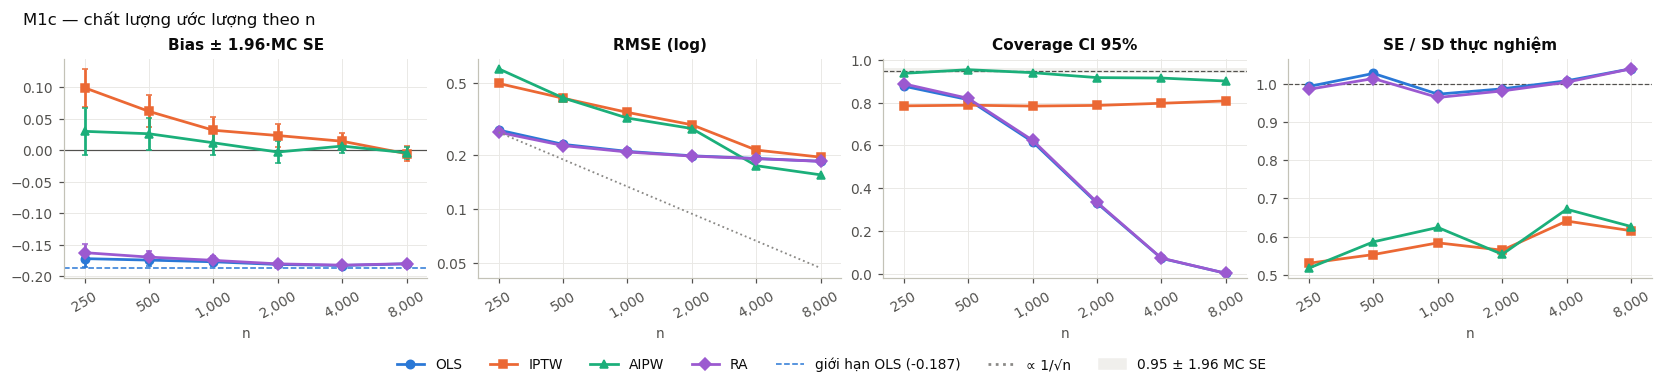

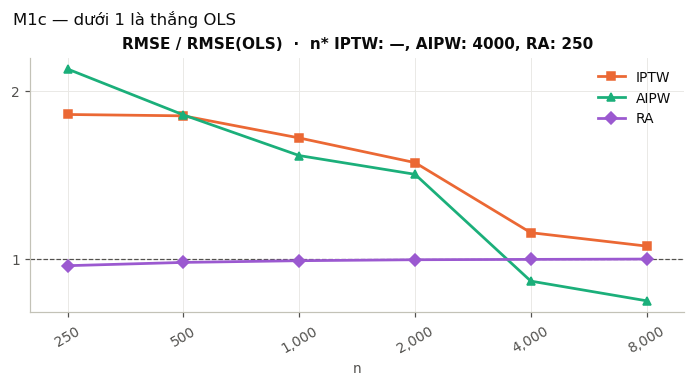

In [38]:
raw_M1c, diag_M1c = run_mc(simulate_M1c, design_linear, "M1c")
summary_M1c = report("M1c", raw_M1c, diag_M1c, LIMIT_M1c)

**Nhận xét M1c.**
- **Kỳ vọng:** OLS, RA ≈ −0.18; IPTW, AIPW ≈ 0 nhưng phương sai rất lớn.
- **Kết quả:** OLS và RA −0.17 đến −0.18, coverage giảm xuống **0.002**. IPTW có **bias mẫu hữu hạn** +0.10 ở n = 250, chỉ về gần 0 ở n = 8000; SE/SD 0.53–0.64 và coverage chỉ khoảng 0.79–0.81 ở mọi n. AIPW tốt hơn nhiều (bias +0.03 → 0, coverage 0.90–0.95) nhưng SE/SD cũng chỉ khoảng 0.52–0.67. Về RMSE, OLS thắng tới n = 2000; AIPW chỉ thắng từ **n = 4000** (0.174 so với 0.191); IPTW không thắng ở n nào trên lưới.
- **Giải thích:** ESS/n giảm từ 0.38 xuống 0.25 và max weight trung bình tăng tới khoảng 190 khi n tăng, vì mẫu lớn hơn có thêm quan sát với e cực đoan. Đây là đánh đổi bias–phương sai rõ nhất: OLS chệch nhưng ổn định; AIPW không chệch tiệm cận nhưng cần n lớn mới hưởng lợi, và CI Wald của nó vẫn quá hẹp.

## Tổng hợp

Gộp mọi kịch bản: bias và coverage theo n, giới hạn OLS trên mẫu lớn, n* (n nhỏ nhất mà từ đó trở đi estimator có RMSE thấp hơn OLS; "—" là không có trên lưới n).
Kết quả lưu ở `results/part_D_summary.csv`, `results/part_D_diagnostic_summary.csv`, `results/part_D_metadata.json`.

In [39]:
ORDER = list(RESULTS)
summary_D = pd.concat([RESULTS[s][0] for s in ORDER], ignore_index=True)
diag_D = pd.concat([RESULTS[s][1].reset_index() for s in ORDER], ignore_index=True)
summary_D.to_csv(RESULT_DIR / "part_D_summary.csv", index=False)
diag_D.to_csv(RESULT_DIR / "part_D_diagnostic_summary.csv", index=False)

for value, fmt in (("bias", "{:+.3f}"), ("coverage", "{:.3f}")):
    wide = (summary_D[summary_D.method.isin(ADJUSTED)]
            .pivot_table(index=["scenario", "method"], columns="n", values=value, sort=False)
            .reindex(pd.MultiIndex.from_product([ORDER, ADJUSTED])))
    display(Markdown(f"**{value} theo n**"))
    display(wide.style.format(fmt))

overview = pd.DataFrame({
    s: {"giới hạn OLS (n = 2·10⁶)": RESULTS[s][2]["ols_bias"],
        **{f"giới hạn {m}": RESULTS[s][2]["table"].loc[m, "bias"] for m in ("IPTW", "AIPW", "RA")},
        "ESS/n (n lớn nhất)": RESULTS[s][1]["ess_ratio"].iloc[-1],
        **{f"n* {m}": n_star(RESULTS[s][0], m) or "—" for m in ("IPTW", "AIPW", "RA")}}
    for s in ORDER}).T
display(Markdown("**Giới hạn bias trên mẫu lớn và n***"))
display(overview.style.format({c: "{:+.3f}" for c in overview.columns if c.startswith("giới hạn")}
                              | {"ESS/n (n lớn nhất)": "{:.2f}"}))

**bias theo n**

**coverage theo n**

**Giới hạn bias trên mẫu lớn và n***

,giới hạn OLS (n = 2·10⁶),giới hạn IPTW,giới hạn AIPW,giới hạn RA,ESS/n (n lớn nhất),n* IPTW,n* AIPW,n* RA
H0,+0.002,+0.001,+0.001,+0.001,0.49,—,—,—
H1a,+0.000,-0.000,+0.000,+0.000,0.88,—,—,2000
H1b,+0.141,+0.001,+0.001,+0.001,0.49,500.000000,250.000000,250.000000
H2,-0.121,+0.002,+0.002,+0.002,0.77,250.000000,250.000000,250.000000
H3,-0.071,+0.001,+0.001,-0.071,0.87,500,500,—
M1a,-0.018,+0.001,+0.001,-0.018,0.87,—,—,250
M1b,-0.091,-0.002,-0.001,-0.091,0.54,8000.000000,8000.000000,250.000000
M1c,-0.187,+0.013,+0.009,-0.187,0.25,—,4000,250


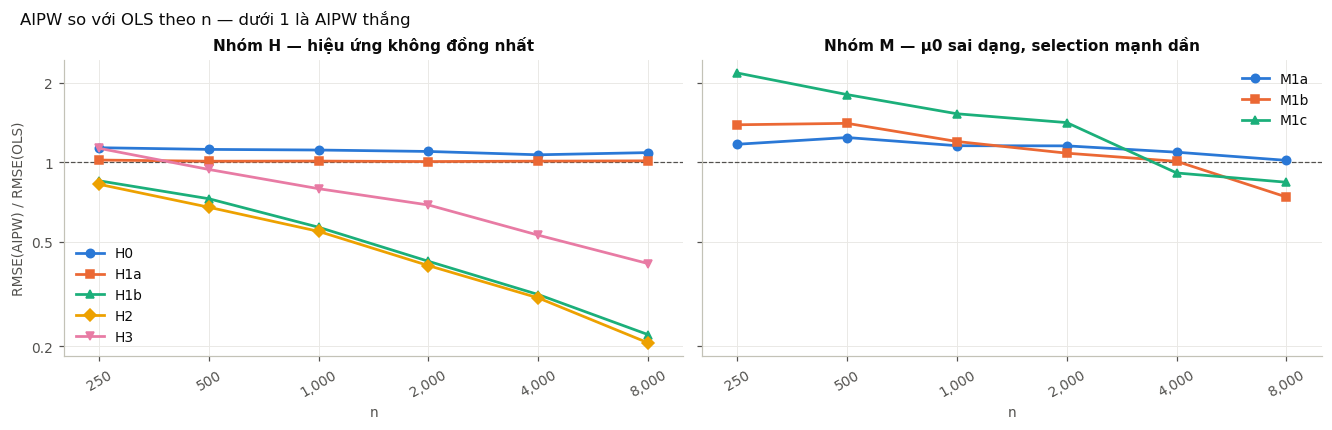

Đã lưu part_D_summary.csv, part_D_diagnostic_summary.csv, part_D_metadata.json


In [40]:
groups = {"Nhóm H — hiệu ứng không đồng nhất": [s for s in ORDER if s.startswith("H")],
          "Nhóm M — μ0 sai dạng, selection mạnh dần": [s for s in ORDER if s.startswith("M")]}
markers = "os^Dv"
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, layout="constrained")
for ax, (title, names) in zip(axes, groups.items()):
    ax.axhline(1, color=INK_2, lw=.8, ls="--")
    for i, s in enumerate(names):
        r = RESULTS[s][0].pivot(index="n", columns="method", values="rmse").sort_index()
        ax.plot(r.index, r["AIPW"]/r["OLS"], color=CATEGORICAL[i], marker=markers[i], label=s)
    style_n_axis(ax, N_VALUES)
    log_y(ax)
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.legend(loc="best")
axes[0].set_ylabel("RMSE(AIPW) / RMSE(OLS)")
fig.suptitle("AIPW so với OLS theo n — dưới 1 là AIPW thắng", x=0.01, ha="left")
fig.savefig(FIG_DIR / "overview_aipw_vs_ols.png", bbox_inches="tight")
plt.show()

metadata = {"part": "D", "R": int(summary_D.R.max()), "seed": SEED, "n": list(N_VALUES),
            "tau": TAU, "sigma": SIGMA, "n_ref": N_REF, "n_large": N_LARGE,
            "constants": {"H1_delta": 0.5, "H2_rare_e": 0.90, "H2_tau_jump": 2.0,
                          "H3_delta": 1.0, "M1_kappa": KAPPA_M1, "M1_gamma": [0.5, 1.0, 1.5]},
            "gamma0": {s: float(globals()[f"GAMMA0_{s}"]) for s in ORDER},
            "H2_rare_shift": float(RARE_SHIFT_H2),
            "large_sample_bias": {s: RESULTS[s][2]["table"]["bias"].round(5).to_dict() for s in ORDER}}
(RESULT_DIR / "part_D_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False),
                                                encoding="utf-8")
print("Đã lưu part_D_summary.csv, part_D_diagnostic_summary.csv, part_D_metadata.json")

## Kết luận

Lưới n = 250 … 8000, R = 1000. Giới hạn bias lấy từ một mẫu n = 2·10⁶; n* là n nhỏ nhất mà từ đó trở đi estimator có RMSE thấp hơn OLS.

| Kịch bản | Giới hạn bias OLS | RA | IPTW | AIPW | Coverage OLS n = 8000 | n* AIPW |
|---|---|---|---|---|---|---|
| **H0** | +0.002 | +0.001 | +0.001 | +0.001 | 0.948 | — |
| **H1a** | +0.000 | +0.000 | −0.000 | +0.000 | 0.950 | — |
| **H1b** | **+0.141** | +0.001 | +0.001 | +0.001 | **0.007** | 250 |
| **H2** | **−0.121** | +0.002 | +0.002 | +0.002 | **0.002** | 250 |
| **H3** | **−0.071** | **−0.071** | +0.001 | +0.001 | 0.288 | 500 |
| **M1a** | −0.018 | −0.018 | +0.001 | +0.001 | 0.911 | — |
| **M1b** | **−0.091** | **−0.091** | −0.002 | −0.001 | 0.242 | 8000 |
| **M1c** | **−0.187** | **−0.187** | +0.013 | +0.009 | 0.002 | 4000 |

1. **OLS chỉ chệch khi hai điều kiện xảy ra cùng lúc.** Riêng lệch tỉ lệ điều trị (**H0**) hay riêng heterogeneity đối xứng (**H1a**) không đủ. Khi τ(X) khác nhau giữa vùng e ≈ 0.5 và vùng e gần 0/1 (**H1b**, **H2**, **H3**), OLS ước lượng một trung bình có trọng số e(1−e) khác ATE. Bias này không giảm theo n, nên coverage về gần 0.
2. **Nhiều trường hợp chỉ cần thêm tương tác.** Ở **H1b** và **H2**, RA (hồi quy riêng từng nhóm) không chệch và thắng OLS từ n = 250, ngang AIPW. Lỗi nằm ở việc OLS dùng một hệ số chung cho A.
3. **AIPW có giá trị riêng khi mô hình outcome sai dạng mà PS đúng** (**H3**, **M1b**, **M1c**). Ở đó RA chệch như OLS, còn AIPW (và IPTW) không chệch tiệm cận. Đây là tính double robust mà phần A không thể hiện được, vì ở phần A PS và outcome luôn đúng hoặc sai cùng lúc.
4. **Không chệch không có nghĩa là thắng.** Khi selection mạnh (**M1b/c**), ESS/n giảm còn 0.25–0.55, IPTW/AIPW có đuôi dày và SE dựa trên IF thấp hơn SD thực tế (SE/SD khoảng 0.5–0.9). AIPW chỉ thắng OLS về RMSE từ n = 4000–8000. IPTW ở **M1c** còn chệch mẫu hữu hạn và có coverage khoảng 0.8. Khi overlap kém, nên đọc kèm ESS và cân nhắc trimming hoặc overlap weights; đó là hướng mở rộng tiếp theo.
5. **Gần double robust của OLS là có thật nhưng mong manh.** Ở **M1a** (γ = 0.5), μ0 sai dạng chỉ gây bias −0.018. Bias tăng lên −0.09 và −0.19 khi γ tăng lên 1.0 và 1.5. Như vậy kết quả "OLS tốt nhất" của phần A phụ thuộc vào việc selection yếu.